In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/sample_submission.zip


In [2]:
#!pip install pyspark

In [3]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.2


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, isnan, lit, to_timestamp
from pyspark.sql.types import DoubleType, IntegerType

In [5]:
spark = SparkSession.builder \
    .appName("NYC Taxi Big Data Analysis") \
    .getOrCreate()
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/24 15:12:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [6]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
  inflating: /kaggle/working/train.csv  


In [7]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
  inflating: /kaggle/working/test.csv  


In [8]:
!ls /kaggle/working/

__notebook__.ipynb  test.csv  train.csv


In [9]:
df_train=spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/train.csv")

In [10]:
df_test =spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/test.csv")

In [11]:
df_train.printSchema()

root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- trip_duration: integer (nullable = true)



In [12]:
df_test.show(truncate=False, vertical=True,n=2)

-RECORD 0---------------------------------
 id                 | id3004672           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:58 
 passenger_count    | 1                   
 pickup_longitude   | -73.98812866210938  
 pickup_latitude    | 40.73202896118164   
 dropoff_longitude  | -73.99017333984375  
 dropoff_latitude   | 40.75667953491211   
 store_and_fwd_flag | N                   
-RECORD 1---------------------------------
 id                 | id3505355           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:53 
 passenger_count    | 1                   
 pickup_longitude   | -73.96420288085938  
 pickup_latitude    | 40.67999267578125   
 dropoff_longitude  | -73.95980834960938  
 dropoff_latitude   | 40.65540313720703   
 store_and_fwd_flag | N                   
only showing top 2 rows


In [13]:
df_train.show(truncate=False, vertical=True,n=6)

-RECORD 0---------------------------------
 id                 | id2875421           
 vendor_id          | 2                   
 pickup_datetime    | 2016-03-14 17:24:55 
 dropoff_datetime   | 2016-03-14 17:32:30 
 passenger_count    | 1                   
 pickup_longitude   | -73.9821548461914   
 pickup_latitude    | 40.76793670654297   
 dropoff_longitude  | -73.96463012695312  
 dropoff_latitude   | 40.765602111816406  
 store_and_fwd_flag | N                   
 trip_duration      | 455                 
-RECORD 1---------------------------------
 id                 | id2377394           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-12 00:43:35 
 dropoff_datetime   | 2016-06-12 00:54:38 
 passenger_count    | 1                   
 pickup_longitude   | -73.98041534423828  
 pickup_latitude    | 40.738563537597656  
 dropoff_longitude  | -73.99948120117188  
 dropoff_latitude   | 40.73115158081055   
 store_and_fwd_flag | N                   
 trip_durat

**Missing value **

In [14]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, FloatType

def check_nulls(df):
    exprs = []
    for field in df.schema.fields:
        c = field.name
        # isnan is only valid for DoubleType / FloatType
        if isinstance(field.dataType, (DoubleType, FloatType)):
            exprs.append(
                F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c)
            )
        else:
            exprs.append(
                F.count(F.when(F.col(c).isNull(), c)).alias(c)
            )
    return df.select(*exprs)

check_nulls(df_train).show(truncate=False,vertical=True)
check_nulls(df_test).show(truncate=False,vertical=True)

-RECORD 0-----------------
 id                 | 0   
 vendor_id          | 0   
 pickup_datetime    | 0   
 dropoff_datetime   | 0   
 passenger_count    | 0   
 pickup_longitude   | 0   
 pickup_latitude    | 0   
 dropoff_longitude  | 0   
 dropoff_latitude   | 0   
 store_and_fwd_flag | 0   
 trip_duration      | 0   



-RECORD 0-----------------
 id                 | 0   
 vendor_id          | 0   
 pickup_datetime    | 0   
 passenger_count    | 0   
 pickup_longitude   | 0   
 pickup_latitude    | 0   
 dropoff_longitude  | 0   
 dropoff_latitude   | 0   
 store_and_fwd_flag | 0   



In [15]:
from pyspark.sql.functions import log1p
from pyspark.sql import functions as F

# Summary statistics
df_train.select(
    F.min("trip_duration").alias("min_duration"),
    F.max("trip_duration").alias("max_duration"),
    F.mean("trip_duration").alias("mean_duration"),
    F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
    F.expr("percentile_approx(trip_duration, 0.99)").alias("p99_duration")
).show(truncate=False)

# Flag outliers using IQR method in Spark
bounds = df_train.select(
    F.expr("percentile_approx(trip_duration, 0.25)").alias("q1"),
    F.expr("percentile_approx(trip_duration, 0.75)").alias("q3")
).collect()[0]
q1, q3 = bounds.q1, bounds.q3
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

print(f"IQR bounds: [{lower_bound}, {upper_bound}]")

# Add outlier flag and log-transformed target
df_train = df_train.withColumn("log_trip_duration", log1p("trip_duration"))
df_train = df_train.withColumn(
    "duration_outlier",
    when((col("trip_duration") < lower_bound) | (col("trip_duration") > upper_bound), 1).otherwise(0)
)


+------------+------------+-----------------+---------------+------------+
|min_duration|max_duration|mean_duration    |median_duration|p99_duration|
+------------+------------+-----------------+---------------+------------+
|1           |3526282     |959.4922729603659|662            |3438        |
+------------+------------+-----------------+---------------+------------+



IQR bounds: [0, 2092.0]


# Optional: hard clip to reasonable range (e.g., 1% - 99%) and remove zero-duration trips


In [16]:
# percs = df_train.select(
#     F.expr("percentile_approx(trip_duration, 0.01)").alias("p01"),
#     F.expr("percentile_approx(trip_duration, 0.99)").alias("p99")
# ).collect()[0]

# df_train_clean = df_train.filter(
#     (col("trip_duration") > 0) &
#     (col("trip_duration") >= percs.p01) &
#     (col("trip_duration") <= percs.p99)
# )

Time Duration 

In [17]:
from pyspark.sql.functions import (
    hour, dayofweek, month, year, 
    when, to_timestamp, col
)

# Ensure datetime format
df_train = df_train.withColumn("pickup_datetime", to_timestamp("pickup_datetime"))
df_test = df_test.withColumn("pickup_datetime", to_timestamp("pickup_datetime"))

# Train has dropoff_datetime; test does not
df_train = df_train.withColumn("dropoff_datetime", to_timestamp("dropoff_datetime"))

def add_datetime_features(df):
    df = df.withColumn("pickup_hour", hour("pickup_datetime"))
    df = df.withColumn("pickup_dayofweek", dayofweek("pickup_datetime"))  # 1=Sun, 7=Sat
    df = df.withColumn("pickup_month", month("pickup_datetime"))
    df = df.withColumn("pickup_year", year("pickup_datetime"))
    
    # Weekend flag (Saturday=7, Sunday=1)
    df = df.withColumn("is_weekend", when(col("pickup_dayofweek").isin([1, 7]), 1).otherwise(0))
    
    # Rush hour flags (morning 7-9, evening 17-19)
    df = df.withColumn(
        "is_rush_hour",
        when(
            ((col("pickup_hour") >= 7) & (col("pickup_hour") <= 9)) |
            ((col("pickup_hour") >= 17) & (col("pickup_hour") <= 19)), 
            1
        ).otherwise(0)
    )
    return df

df_train = add_datetime_features(df_train)
df_test = add_datetime_features(df_test)

# Sanity check: compute duration from timestamps on train
df_train = df_train.withColumn(
    "duration_from_delta",
    col("dropoff_datetime").cast("long") - col("pickup_datetime").cast("long")
)

# Check how many rows have mismatched durations
mismatch_count = df_train.filter(
    F.abs(col("duration_from_delta") - col("trip_duration")) > 60
).count()
print(f"Timestamp-derived mismatches (>60s): {mismatch_count}")

Timestamp-derived mismatches (>60s): 0


In [18]:
# before = df_train.count()

# #df_train_clean = filter_nyc_bounds(df_train)

# after = df_train_clean.count()

# print("Before:", before)
# print("After:", after)
# print("Removed:", before - after)

In [19]:
from pyspark.sql.functions import radians, sin, cos, atan2, sqrt, lit

# NYC approximate bounds
MIN_LON, MAX_LON = -74.3, -73.7
MIN_LAT, MAX_LAT = 40.4, 40.9

def filter_nyc_bounds(df):
    return df.filter(
        (col("pickup_longitude").between(MIN_LON, MAX_LON)) &
        (col("pickup_latitude").between(MIN_LAT, MAX_LAT)) &
        (col("dropoff_longitude").between(MIN_LON, MAX_LON)) &
        (col("dropoff_latitude").between(MIN_LAT, MAX_LAT))
    )

df_train = filter_nyc_bounds(df_train)
df_test = filter_nyc_bounds(df_test)

# Remove identical pickup/dropoff
df_train = df_train.withColumn(
    "same_pickup_dropoff",
    when(
        (col("pickup_longitude") == col("dropoff_longitude")) &
        (col("pickup_latitude") == col("dropoff_latitude")), 
        1
    ).otherwise(0)
)

df_test = df_test.withColumn(
    "same_pickup_dropoff",
    when(
        (col("pickup_longitude") == col("dropoff_longitude")) &
        (col("pickup_latitude") == col("dropoff_latitude")), 
        1
    ).otherwise(0)
)

# Haversine distance (km)
def add_haversine(df):
    return df.withColumn(
        "haversine_km",
        lit(6371) * 2 * atan2(
            sqrt(
                sin((radians(col("dropoff_latitude") - col("pickup_latitude"))) / 2) ** 2 +
                cos(radians(col("pickup_latitude"))) * 
                cos(radians(col("dropoff_latitude"))) *
                sin((radians(col("dropoff_longitude") - col("pickup_longitude"))) / 2) ** 2
            ),
            sqrt(1 - (
                sin((radians(col("dropoff_latitude") - col("pickup_latitude"))) / 2) ** 2 +
                cos(radians(col("pickup_latitude"))) * 
                cos(radians(col("dropoff_latitude"))) *
                sin((radians(col("dropoff_longitude") - col("pickup_longitude"))) / 2) ** 2
            ))
        )
    )

df_train = add_haversine(df_train)
df_test = add_haversine(df_test)

# Remove zero-distance outliers if needed
df_train = df_train.filter(col("haversine_km") > 0)

In [20]:
# Check value distribution
df_train.groupBy("passenger_count").count().orderBy("passenger_count").show()
df_train = df_train.withColumn(
    "passenger_count",
    when(col("passenger_count") > 6, 6).otherwise(col("passenger_count"))
)
df_test = df_test.withColumn(
    "passenger_count",
    when(col("passenger_count") > 6, 6).otherwise(col("passenger_count"))
)
df_train.groupBy("passenger_count").count().orderBy("passenger_count").show()

+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|              0|     52|
|              1|1028194|
|              2| 209289|
|              3|  59639|
|              4|  28234|
|              5|  77749|
|              6|  48033|
|              7|      2|
|              8|      1|
+---------------+-------+



+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|              0|     52|
|              1|1028194|
|              2| 209289|
|              3|  59639|
|              4|  28234|
|              5|  77749|
|              6|  48036|
+---------------+-------+



In [21]:
# Distribution
df_train.groupBy("store_and_fwd_flag").count().show()

# Relationship with trip duration
df_train.groupBy("store_and_fwd_flag").agg(
    F.mean("trip_duration").alias("avg_duration"),
    F.median("trip_duration").alias("median_duration"),  # Spark 3.4+; else use percentile_approx
    F.count("*").alias("trip_count")
).show()


df_train = df_train.withColumn(
    "store_and_fwd_flag_y",
    when(col("store_and_fwd_flag") == "Y", 1).otherwise(0)
)
df_test = df_test.withColumn(
    "store_and_fwd_flag_y",
    when(col("store_and_fwd_flag") == "Y", 1).otherwise(0)
)

+------------------+-------+
|store_and_fwd_flag|  count|
+------------------+-------+
|                 Y|   7959|
|                 N|1443234|
+------------------+-------+



+------------------+------------------+---------------+----------+
|store_and_fwd_flag|      avg_duration|median_duration|trip_count|
+------------------+------------------+---------------+----------+
|                 Y|1084.0770197260963|          816.0|      7959|
|                 N| 958.8548738458213|          662.0|   1443234|
+------------------+------------------+---------------+----------+



In [22]:
df_train.show(n=1,vertical=True)

-RECORD 0-----------------------------------
 id                   | id2875421           
 vendor_id            | 2                   
 pickup_datetime      | 2016-03-14 17:24:55 
 dropoff_datetime     | 2016-03-14 17:32:30 
 passenger_count      | 1                   
 pickup_longitude     | -73.9821548461914   
 pickup_latitude      | 40.76793670654297   
 dropoff_longitude    | -73.96463012695312  
 dropoff_latitude     | 40.765602111816406  
 store_and_fwd_flag   | N                   
 trip_duration        | 455                 
 log_trip_duration    | 6.1224928095143865  
 duration_outlier     | 0                   
 pickup_hour          | 17                  
 pickup_dayofweek     | 2                   
 pickup_month         | 3                   
 pickup_year          | 2016                
 is_weekend           | 0                   
 is_rush_hour         | 1                   
 duration_from_delta  | 455                 
 same_pickup_dropoff  | 0                   
 haversine

In [23]:
df_train = df_train.drop("store_and_fwd_flag")
df_test = df_test.drop("store_and_fwd_flag")

In [24]:
df_train.show(n=1,vertical=True)

-RECORD 0-----------------------------------
 id                   | id2875421           
 vendor_id            | 2                   
 pickup_datetime      | 2016-03-14 17:24:55 
 dropoff_datetime     | 2016-03-14 17:32:30 
 passenger_count      | 1                   
 pickup_longitude     | -73.9821548461914   
 pickup_latitude      | 40.76793670654297   
 dropoff_longitude    | -73.96463012695312  
 dropoff_latitude     | 40.765602111816406  
 trip_duration        | 455                 
 log_trip_duration    | 6.1224928095143865  
 duration_outlier     | 0                   
 pickup_hour          | 17                  
 pickup_dayofweek     | 2                   
 pickup_month         | 3                   
 pickup_year          | 2016                
 is_weekend           | 0                   
 is_rush_hour         | 1                   
 duration_from_delta  | 455                 
 same_pickup_dropoff  | 0                   
 haversine_km         | 1.4985207796474773  
 store_and

In [25]:
# Basic vendor stats
vendor_stats = df_train.groupBy("vendor_id").agg(
    F.count("*").alias("trip_count"),
    F.mean("trip_duration").alias("avg_duration"),
    F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
    F.mean("haversine_km").alias("avg_distance_km"),
    F.mean("passenger_count").alias("avg_passenger_count")
)
vendor_stats.show(truncate=False,vertical=True)

# Compare weekend vs weekday by vendor
df_train.groupBy("vendor_id", "is_weekend").agg(
    F.mean("trip_duration").alias("avg_duration"),
    F.count("*").alias("trips")
).orderBy("vendor_id", "is_weekend").show(truncate=False,vertical=True)

-RECORD 0---------------------------------
 vendor_id           | 1                  
 trip_count          | 675363             
 avg_duration        | 845.8811972228268  
 median_duration     | 659                
 avg_distance_km     | 3.386204148920182  
 avg_passenger_count | 1.2595152532786071 
-RECORD 1---------------------------------
 vendor_id           | 2                  
 trip_count          | 775830             
 avg_duration        | 1058.4835092739388 
 median_duration     | 666                
 avg_distance_km     | 3.4664659627981593 
 avg_passenger_count | 2.0171377750280346 



-RECORD 0--------------------------
 vendor_id    | 1                  
 is_weekend   | 0                  
 avg_duration | 865.515301510604   
 trips        | 483449             
-RECORD 1--------------------------
 vendor_id    | 1                  
 is_weekend   | 1                  
 avg_duration | 796.4210844440739  
 trips        | 191914             
-RECORD 2--------------------------
 vendor_id    | 2                  
 is_weekend   | 0                  
 avg_duration | 1066.5590305123444 
 trips        | 553612             
-RECORD 3--------------------------
 vendor_id    | 2                  
 is_weekend   | 1                  
 avg_duration | 1038.3649524340963 
 trips        | 222218             



Vendor 2 has ~15% more trips but a 25% higher average duration despite nearly identical median duration and distance, suggesting outlier-driven skew. Passenger count also differs sharply (1.26 vs 2.02), hinting at different recording or rider profiles.

Weekend vs weekday: Both vendors show slightly shorter trips on weekends, but Vendor 1's weekend speed-up (−8%) is stronger than Vendor 2's (−2.6%). Vendor 2 remains consistently slower regardless of day type, and both keep a similar ~72/28 weekday/weekend trip split.

In [26]:
# import time
# import seaborn as sns
# import matplotlib.pyplot as plt
# from pyspark.sql import functions as F

# start = time.time()

# # ─── گام 1: محاسبه میانگین در PySpark ───
# summary_wdays_avg_duration = (
#     df_train
#     .groupBy('vendor_id', 'day_of_week')
#     .agg(F.mean('trip_duration').alias('avg_duration'))
#     .orderBy('vendor_id', 'day_of_week')
# )

# # ─── گام 2: تبدیل به Pandas برای رسم ───
# summary_pd = summary_wdays_avg_duration.toPandas()

# # ─── گام 3: تنظیمات Seaborn ───
# sns.set_theme(style="white", context="poster")

# # ─── گام 4: رسم ───
# plt.figure(figsize=(12, 6))
# sns.lineplot(
#     data=summary_pd,
#     x="day_of_week",
#     y="avg_duration",
#     hue="vendor_id",
#     marker="o",
#     palette="muted"
# )
# sns.despine(bottom=False)

# plt.title("میانگین مدت سفر بر اساس روز هفته و vendor")
# plt.xlabel("روز هفته")
# plt.ylabel("میانگین مدت سفر (ثانیه)")
# plt.xticks(range(1, 8), ['Sun','Mon','Tue','Wed','Thu','Fri','Sat'])
# plt.tight_layout()
# plt.show()

# end = time.time()
# print(f"⏱️ زمان اجرا: {end - start:.2f} ثانیه")

**no duplicate found **

In [27]:
total_rows = df_train.count()
distinct_rows = df_train.distinct().count()

print(f"Total rows:     {total_rows:,}")
print(f"Distinct rows:  {distinct_rows:,}")
print(f"Duplicates:     {total_rows - distinct_rows:,}")
df_train.groupBy("id") \
    .count() \
    .filter(F.col("count") > 1) \
    .show()

Total rows:     1,451,193
Distinct rows:  1,451,193
Duplicates:     0


+---+-----+
| id|count|
+---+-----+
+---+-----+



In [28]:
df_train.select("trip_duration").summary().show()

+-------+-----------------+
|summary|    trip_duration|
+-------+-----------------+
|  count|          1451193|
|   mean| 959.541648836509|
| stddev|5246.300468667948|
|    min|                1|
|    25%|              398|
|    50%|              663|
|    75%|             1075|
|    max|          3526282|
+-------+-----------------+



* Extreme Outlier Presence: The max duration of $\approx 3,526,282$ seconds ($\approx 40$ days) alongside a high standard deviation ($5,246$ s) relative to the mean ($959$ s) indicates severe outliers, likely due to unended meter trips, GPS anomalies, or data entry errors.
* Skewed Distribution: The median (50th percentile) is $663$ seconds ($\approx 11$ minutes), while the mean is noticeably higher at $959$ seconds, confirming a heavily right-skewed distribution characteristic of urban traffic congestion and long-haul trips.
* Data Cleaning Required: The minimum value of $1$ second and the extreme max value necessitate robust filtering or log transformation (e.g., capping trips between $60$ seconds and $2$ hours) before feeding this target variable into a regression model.

In [29]:
df_train.filter(
    F.col("trip_duration") <= 0
).count()

0

In [30]:
df_train.filter(F.col("trip_duration") > 86400) \
    .select("id", "trip_duration", "pickup_datetime", "dropoff_datetime") \
    .orderBy(F.col("trip_duration").desc()) \
    .show(truncate=False)

+---------+-------------+-------------------+-------------------+
|id       |trip_duration|pickup_datetime    |dropoff_datetime   |
+---------+-------------+-------------------+-------------------+
|id0053347|3526282      |2016-02-13 22:46:52|2016-03-25 18:18:14|
|id1325766|2227612      |2016-01-05 06:14:15|2016-01-31 01:01:07|
|id0369307|2049578      |2016-02-13 22:38:00|2016-03-08 15:57:38|
|id1864733|1939736      |2016-01-05 00:19:42|2016-01-27 11:08:38|
+---------+-------------+-------------------+-------------------+



* **Logical Impossibility:** Trips exceeding 24 hours ($86,400$ seconds) in NYC are invalid for standard taxi operations and point to unclosed meters, system logging errors, or abandoned vehicles.
* **Severe Distortion Risk:** Retaining multi-week anomalies like the $40$-day trip will severely penalize regression metrics (like MSE/RMSE) and distort gradient updates during model training.
* **Actionable Cleaning Rule:** Implement a strict upper-bound filter to remove or cap any trips lasting longer than a realistic urban threshold (typically $2$ to $3$ hours max).

In [31]:
# percentiles = df_train.approxQuantile(
#     "trip_duration",
#     [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99],
#     0.001
# )

# print(percentiles)
# for p, value in zip(
#     [1, 5, 25, 50, 75, 95, 99],
#     percentiles
# ):
#     print(f"{p}th percentile: {value:.2f} seconds")

In [32]:
# q1, q3 = df_train.approxQuantile(
#     "trip_duration",
#     [0.25, 0.75],
#     0.001
# )

# iqr = q3 - q1

# lower_bound = q1 - 1.5 * iqr
# upper_bound = q3 + 1.5 * iqr

# print("Q1:", q1)
# print("Q3:", q3)
# print("IQR:", iqr)
# print("Lower bound:", lower_bound)
# print("Upper bound:", upper_bound)

In [33]:
# df_train.filter(
#     (F.col("trip_duration") < lower_bound) |
#     (F.col("trip_duration") > upper_bound)
# ).count()

In [34]:
df_train = df_train.withColumn(
    "log_trip_duration",
    F.log1p("trip_duration")
)
df_train.select(
    "trip_duration",
    "log_trip_duration"
).show(10)

+-------------+------------------+
|trip_duration| log_trip_duration|
+-------------+------------------+
|          455|6.1224928095143865|
|          663| 6.498282149476434|
|         2124| 7.661527081358517|
|          429| 6.063785208687608|
|          435| 6.077642243349034|
|          443| 6.095824562432225|
|          341| 5.834810737062605|
|         1551| 7.347299700743164|
|          255| 5.545177444479562|
|         1225| 7.111512116496157|
+-------------+------------------+
only showing top 10 rows


In [35]:
log_sample = df_train.select(
    "log_trip_duration"
).sample(
    withReplacement=False,
    fraction=0.05,
    seed=42
).limit(100000).toPandas()

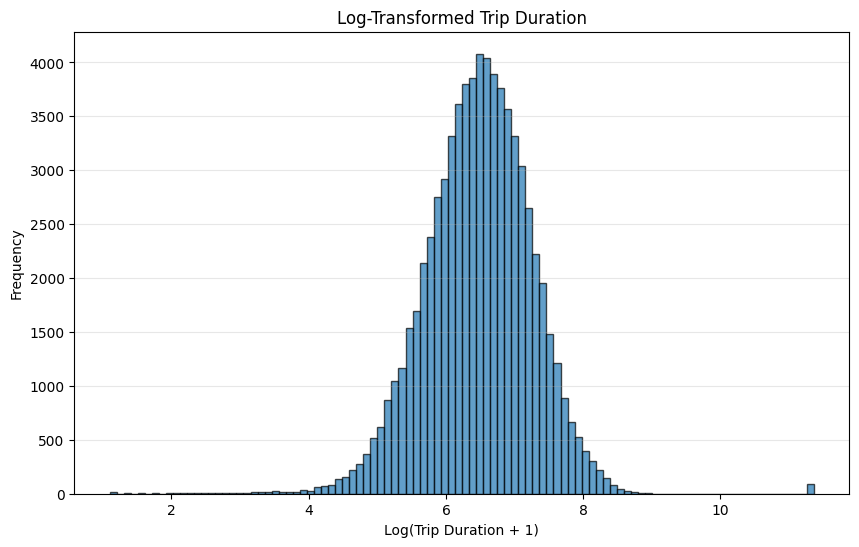

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(log_sample["log_trip_duration"], bins=100, edgecolor="black", alpha=0.7)
plt.xlabel("Log(Trip Duration + 1)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Trip Duration")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [37]:
df_train.groupBy("same_pickup_dropoff").count().show()

+-------------------+-------+
|same_pickup_dropoff|  count|
+-------------------+-------+
|                  0|1451193|
+-------------------+-------+



* **Clean Spatial Baseline:** Every single record features distinct pickup and dropoff coordinates (`same_pickup_dropoff = 0`), confirming that zero-distance or accidental same-spot trips are completely absent from this dataset.
* **Feature Engineering Safety:** This clean boundary eliminates degenerate geometric cases, preventing division-by-zero errors when computing derived metrics like Haversine distance, speed, or bearing.
* **Data Integrity:** It indicates high spatial data quality, allowing you to confidently feed latitude and longitude coordinates into tree-based or spatial models without noisy zero-length anomalies.

In [38]:
from pyspark.sql import functions as F
import time

start = time.time()

hourly_stats = (
    df_train
    .groupBy("pickup_hour")
    .agg(
        F.count("*").alias("trip_count"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance_km"),
        F.mean("is_rush_hour").alias("rush_hour_ratio")
    )
    .orderBy("pickup_hour")
)

hourly_stats.show(24, truncate=False)
print(f"⏱️ {time.time()-start:.2f}s")

+-----------+----------+------------------+---------------+------------------+---------------+
|pickup_hour|trip_count|avg_duration      |median_duration|avg_distance_km   |rush_hour_ratio|
+-----------+----------+------------------+---------------+------------------+---------------+
|0          |52933     |937.2368654714451 |646            |3.984824035201931 |0.0            |
|1          |38342     |900.6287882739555 |613            |3.9281150552505704|0.0            |
|2          |27825     |889.5920215633423 |591            |3.842936328981956 |0.0            |
|3          |20753     |890.5975521611333 |593            |4.085339285673994 |0.0            |
|4          |15660     |919.0700510855684 |612            |4.870268042430335 |0.0            |
|5          |14904     |824.2532206119163 |519            |5.390139135821043 |0.0            |
|6          |33090     |797.990661831369  |474            |4.111546985749189 |0.0            |
|7          |55342     |830.638918000795  |575    

* **Congestion vs. Distance Disconnect:** Mid-afternoon hours (14–16) experience peak durations ($\approx 1,118$ s) despite shorter distances ($\approx 3.4$ km), whereas pre-dawn hours (e.g., hour 5) handle longer distances ($\approx 5.4$ km) much faster due to free-flowing traffic.
* **Demand Surges:** Trip volume heavily spikes during the evening commute (peaking at $>90,000$ trips at 18:00), validating `pickup_hour` as a high-importance cyclical feature for tree-based models.


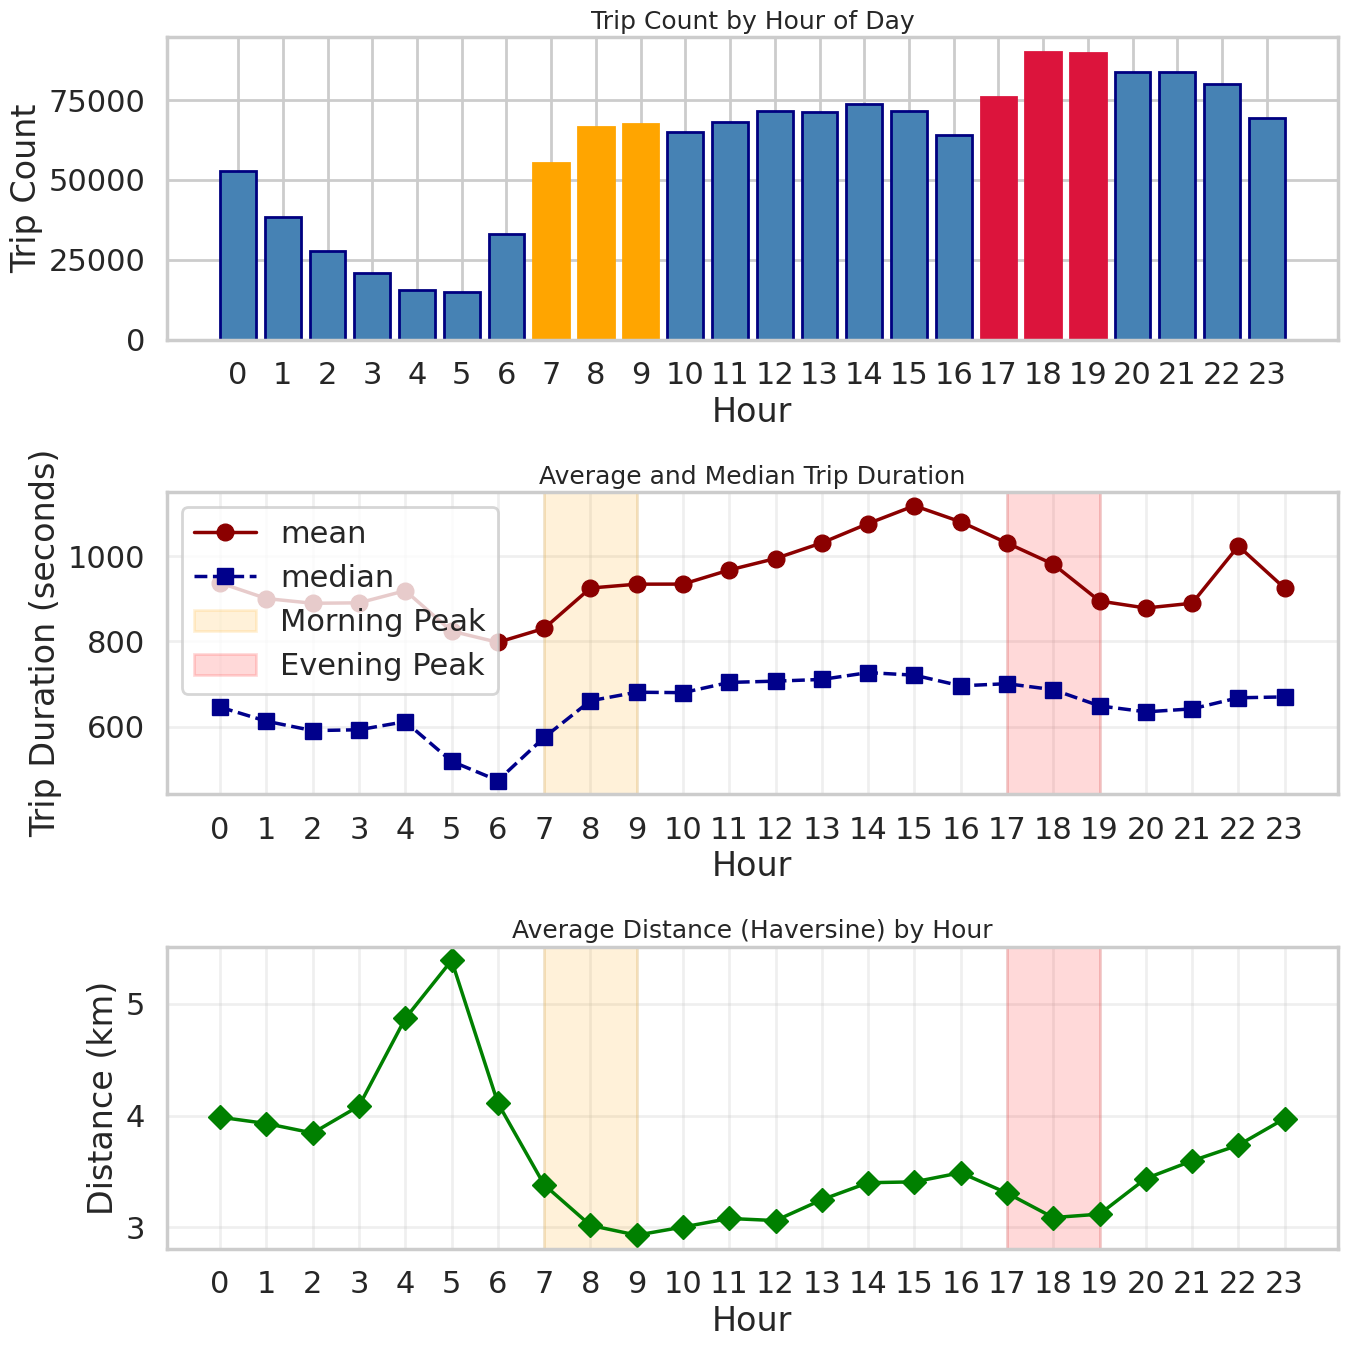

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

hourly_pd = hourly_stats.toPandas()

sns.set_theme(style="whitegrid", context="poster")
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# ─── Chart 1: Trip count ───
bars = axes[0].bar(
    hourly_pd["pickup_hour"],
    hourly_pd["trip_count"],
    color="steelblue",
    edgecolor="navy"
)
# Highlight peaks
for i, h in enumerate(hourly_pd["pickup_hour"]):
    if h in [7, 8, 9]:
        bars[i].set_color("orange")
    elif h in [17, 18, 19]:
        bars[i].set_color("crimson")

axes[0].set_title("Trip Count by Hour of Day", fontsize=18)
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Trip Count")
axes[0].set_xticks(range(24))

# ─── Chart 2: Average duration ───
axes[1].plot(
    hourly_pd["pickup_hour"],
    hourly_pd["avg_duration"],
    marker='o', color="darkred", linewidth=2.5, label="mean"
)
axes[1].plot(
    hourly_pd["pickup_hour"],
    hourly_pd["median_duration"],
    marker='s', color="darkblue", linewidth=2.5, linestyle="--", label="median"
)
axes[1].axvspan(7, 9, alpha=0.15, color='orange', label='Morning Peak')
axes[1].axvspan(17, 19, alpha=0.15, color='red', label='Evening Peak')
axes[1].set_title("Average and Median Trip Duration", fontsize=18)
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Trip Duration (seconds)")
axes[1].set_xticks(range(24))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ─── Chart 3: Average distance ───
axes[2].plot(
    hourly_pd["pickup_hour"],
    hourly_pd["avg_distance_km"],
    marker='D', color="green", linewidth=2.5
)
axes[2].axvspan(7, 9, alpha=0.15, color='orange')
axes[2].axvspan(17, 19, alpha=0.15, color='red')
axes[2].set_title("Average Distance (Haversine) by Hour", fontsize=18)
axes[2].set_xlabel("Hour")
axes[2].set_ylabel("Distance (km)")
axes[2].set_xticks(range(24))
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

* Early morning trips at hour 5 achieve the longest average distance of roughly 5.5 km, yet complete relatively quickly due to open roads.


* Mid-afternoon hours hit peak mean durations exceeding 1,100 seconds despite modest distances around 3.5 km, clearly highlighting severe urban congestion bottlenecks.


* Trip volumes surge sharply during evening hours from 17:00 to 19:00, emphasizing the necessity of robust cyclical time features for downstream models.

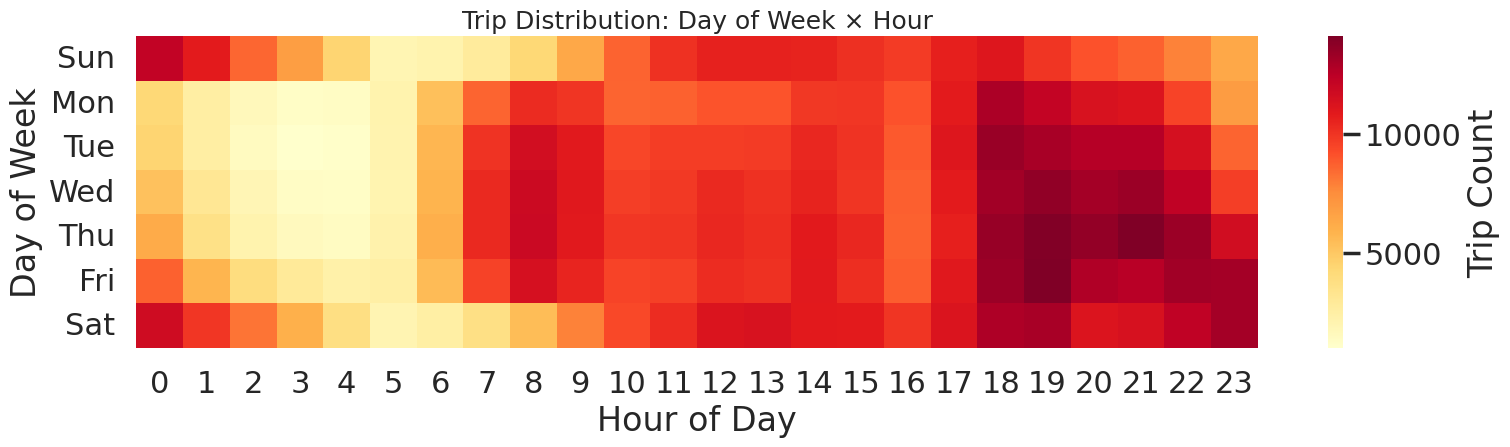

In [40]:
# ─── Double grouping ───
hour_dow = (
    df_train
    .groupBy("pickup_dayofweek", "pickup_hour")
    .agg(F.count("*").alias("trip_count"))
    .orderBy("pickup_dayofweek", "pickup_hour")
)

# ─── Pivot ───
pivot = hour_dow.toPandas().pivot(
    index="pickup_dayofweek",
    columns="pickup_hour",
    values="trip_count"
).fillna(0)

# ─── Plot ───
plt.figure(figsize=(16, 5))
sns.heatmap(
    pivot,
    cmap="YlOrRd",
    annot=False,
    cbar_kws={"label": "Trip Count"}
)
plt.title("Trip Distribution: Day of Week × Hour", fontsize=18)
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.yticks(
    ticks=[i+0.5 for i in range(7)],
    labels=['Sun','Mon','Tue','Wed','Thu','Fri','Sat'],
    rotation=0
)
plt.tight_layout()
plt.show()

* **Commuter vs. Leisure Segregation:** Weekdays (Monday through Friday) exhibit heavy traffic concentrations during the morning (07:00–09:00) and evening rush hours, with peak intensity stretching into late evening (18:00–21:00).


* **Nightlife Surge:** Weekends and Friday nights display a pronounced spike in trip counts during the early morning hours (00:00–03:00), capturing distinct late-night leisure and entertainment patterns.


* **Interaction Feature Necessity:** The clear structural shift between weekday commuting profiles and weekend nightlife behavior highlights the critical need for a combined `day_of_week` and `hour` interaction feature to capture these non-linear temporal dynamics.

In [41]:
rush_stats = (
    df_train
    .groupBy("is_rush_hour")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance")
    )
    .orderBy("is_rush_hour")
)

rush_stats.show(truncate=False)

+------------+-------+-----------------+---------------+------------------+
|is_rush_hour|trips  |avg_duration     |median_duration|avg_distance      |
+------------+-------+-----------------+---------------+------------------+
|0           |1005630|969.0306365164126|664            |3.5610897998323483|
|1           |445563 |938.1251248420538|661            |3.1312441678044842|
+------------+-------+-----------------+---------------+------------------+



* **Counter-Intuitive Metrics:** Non-rush hours ($0$) unexpectedly show higher average durations ($969$ s) and distances ($3.56$ km) than rush hours ($938$ s and $3.13$ km), likely driven by long-distance off-peak trips like late-night airport runs.


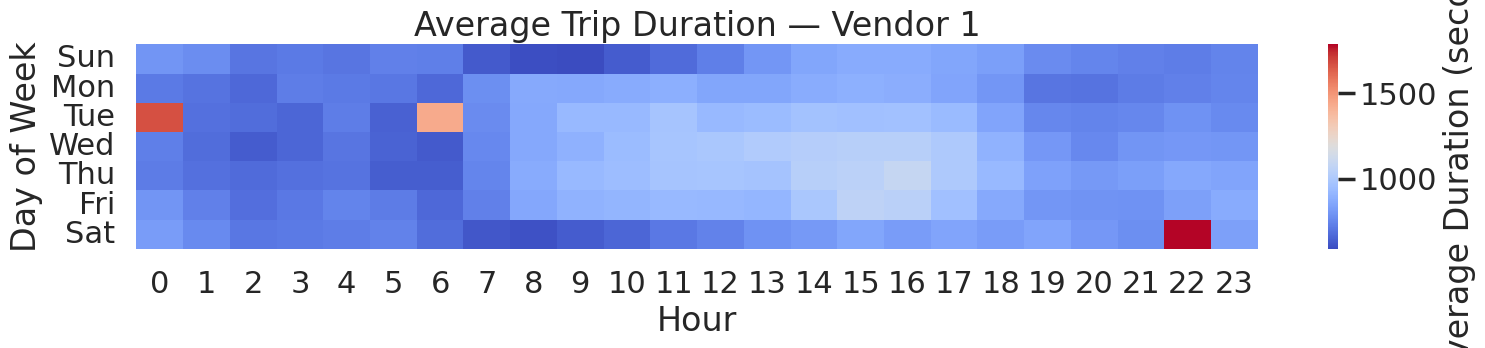

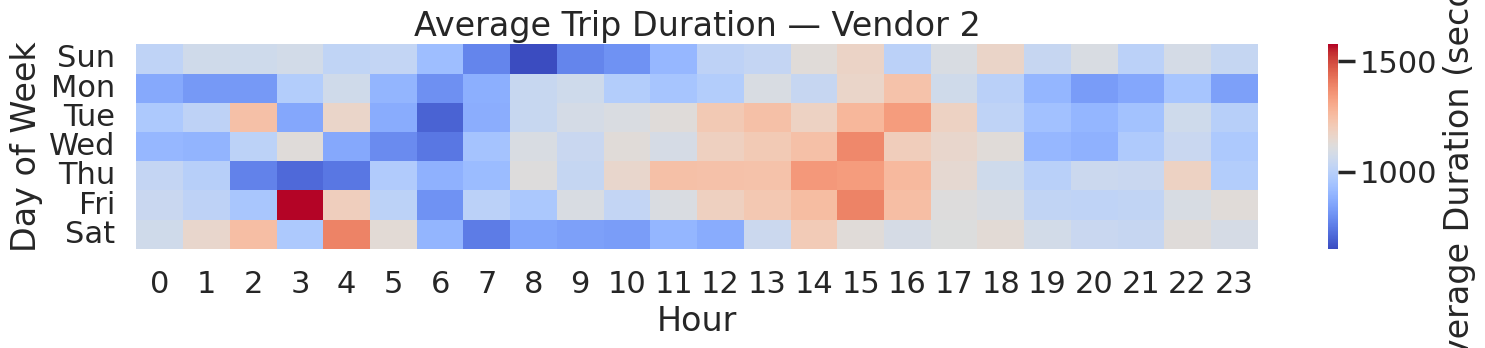

In [42]:
# ─── Compute average duration ───
hour_dow_vendor = (
    df_train
    .groupBy("vendor_id", "pickup_dayofweek", "pickup_hour")
    .agg(
        F.mean("trip_duration").alias("avg_duration"),
        F.count("*").alias("trips")
    )
    .orderBy("vendor_id", "pickup_dayofweek", "pickup_hour")
)

# ─── One heatmap per vendor ───
for vid in [1, 2]:
    subset = hour_dow_vendor.filter(F.col("vendor_id") == vid).toPandas()
    pivot = subset.pivot(
        index="pickup_dayofweek",
        columns="pickup_hour",
        values="avg_duration"
    )

    plt.figure(figsize=(16, 4))
    sns.heatmap(
        pivot, cmap="coolwarm", annot=False,
        cbar_kws={"label": "Average Duration (seconds)"}
    )
    plt.title(f"Average Trip Duration — Vendor {vid}")
    plt.xlabel("Hour")
    plt.ylabel("Day of Week")
    plt.yticks(
        ticks=[i+0.5 for i in range(7)],
        labels=['Sun','Mon','Tue','Wed','Thu','Fri','Sat'],
        rotation=0
    )
    plt.tight_layout()
    plt.show()

* **Vendor Behavioral Divergence:** Vendor 2 exhibits significantly higher average trip durations during mid-day and afternoon hours (11:00–17:00) compared to the relatively uniform baseline of Vendor 1.


* **Isolated Outlier Spikes:** Both heatmaps display extreme localized anomalies—such as Vendor 1's spikes on Tuesday at 06:00 and Saturday at 22:00, and Vendor 2's intense spike on Friday at 03:00—highlighting potential GPS logging errors or rare traffic bottlenecks.


* **Feature Value:** The stark structural difference between the two vendors confirms that `vendor_id` is a critical categorical feature with distinct interaction effects for tree-based models.

🚨 Peak صبح (ساعت 7-9):

In [43]:
from pyspark.sql import functions as F
import time

start = time.time()

# ─── Weekly statistics ───
weekly_stats = (
    df_train
    .groupBy("pickup_dayofweek")
    .agg(
        F.count("*").alias("trip_count"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance_km"),
        F.mean("passenger_count").alias("avg_passengers"),
        F.mean("is_rush_hour").alias("rush_hour_ratio")
    )
    .orderBy("pickup_dayofweek")
)

weekly_stats.show(truncate=False)
print(f"⏱️ {time.time()-start:.2f}s")

+----------------+----------+------------------+---------------+------------------+------------------+-------------------+
|pickup_dayofweek|trip_count|avg_duration      |median_duration|avg_distance_km   |avg_passengers    |rush_hour_ratio    |
+----------------+----------+------------------+---------------+------------------+------------------+-------------------+
|1               |194332    |901.5030566247452 |602            |3.711677009335024 |1.7170100652491613|0.2322983348084721 |
|2               |186444    |897.8665765591813 |631            |3.5504022517517293|1.6340348844693313|0.3472088133702345 |
|3               |201693    |983.6997813508649 |679            |3.332637570385626 |1.6357533479099424|0.3465216938614627 |
|4               |209100    |975.30181252989   |695            |3.331101412378295 |1.632912482065997 |0.33784791965566713|
|5               |217436    |1006.7468266524403|710            |3.409518521911731 |1.638459132802296 |0.3275952464173366 |
|6              

* **Weekend Volume Surge:** Trip counts steadily increase toward the end of the week, peaking on days 5, 6, and 7 (with over 217,000 to 222,000 trips), reflecting a rise in leisure and weekend mobility.
* **Weekday Congestion Drag:** Average durations are consistently higher from mid-week through day 6 (ranging from 975 to 1,006 seconds) despite shorter average distances ($\approx 3.3$–$3.4$ km), pointing to heavy recurring weekday traffic congestion.
* **Weekend Signature:** Days 1 and 7 show a distinct drop in `rush_hour_ratio` ($\approx 0.23$–$0.24$) compared to the remaining days ($\approx 0.31$–$0.35$), identifying them as weekend days where traditional commuting peaks are absent.

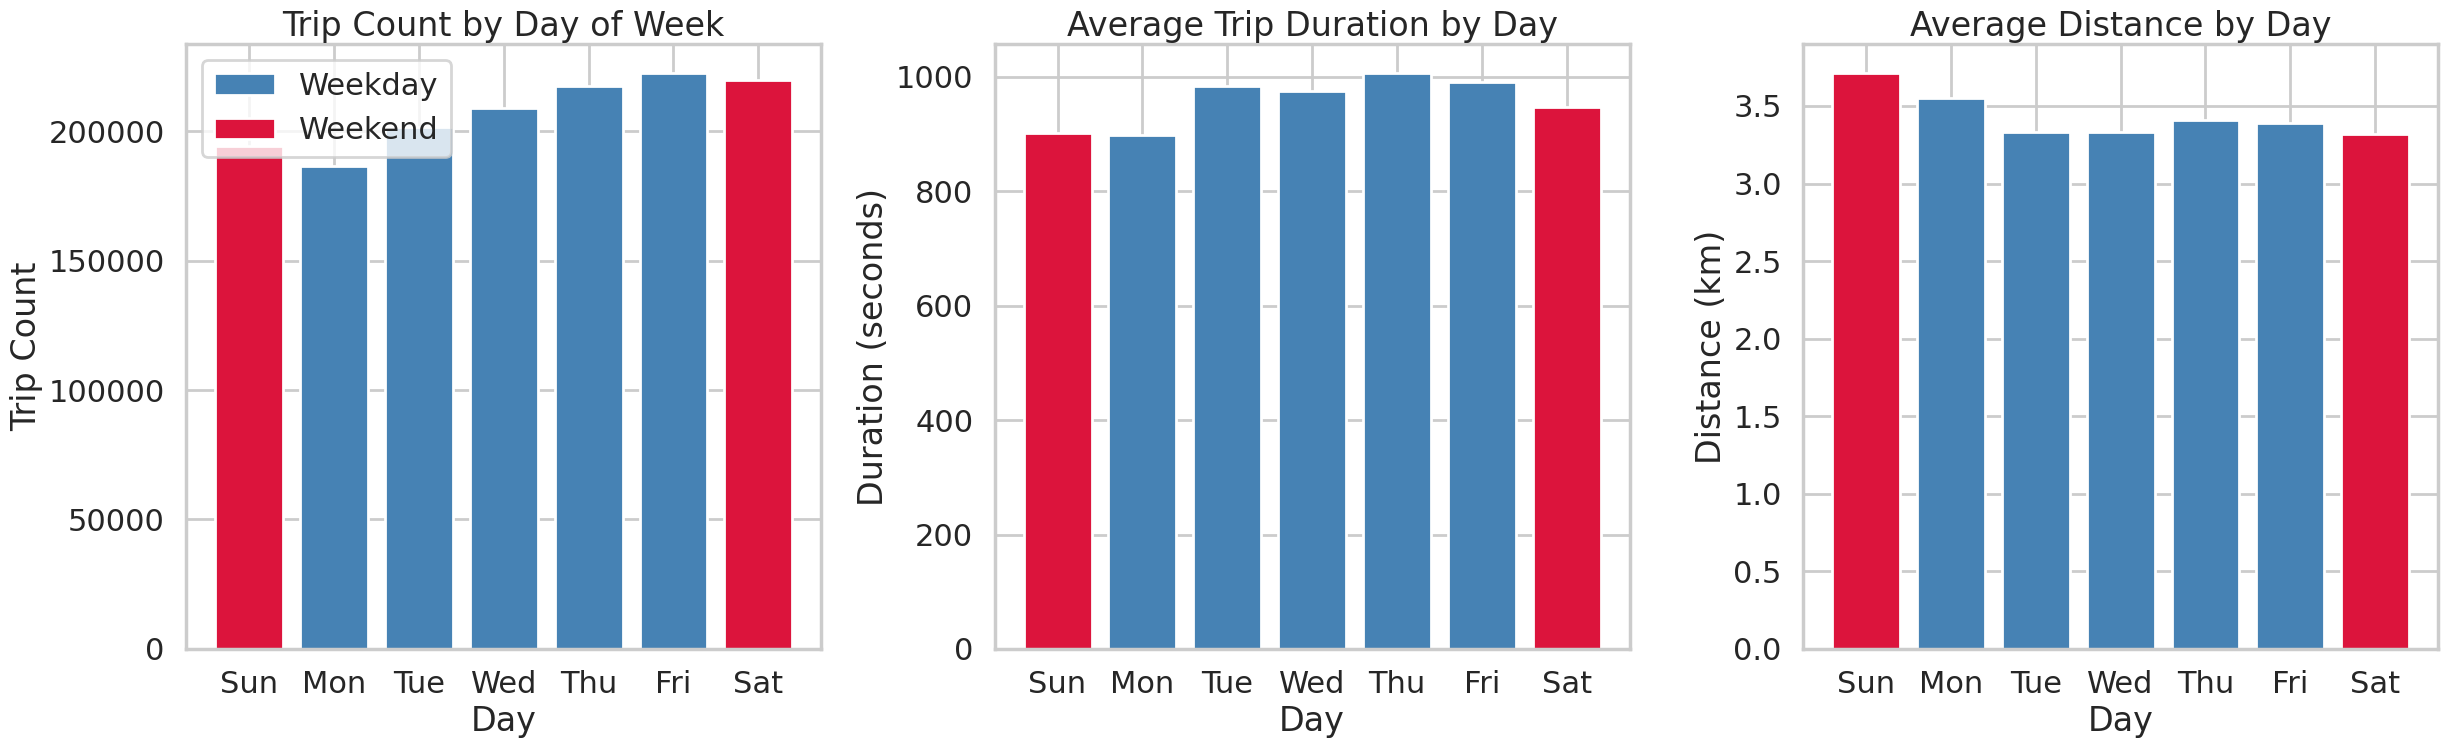

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

weekly_pd = weekly_stats.toPandas()

# ─── Map day numbers to names ───
day_names = ['Sun','Mon','Tue','Wed','Thu','Fri','Sat']
weekly_pd['day_name'] = weekly_pd['pickup_dayofweek'].map(
    lambda x: day_names[x-1]  # Spark: 1=Sun, 2=Mon, ...
)
weekly_pd['is_weekend'] = weekly_pd['pickup_dayofweek'].isin([1, 7])

sns.set_theme(style="whitegrid", context="poster")
fig, axes = plt.subplots(1, 3, figsize=(25, 8))

# ─── Chart 1: Trip count ───
colors = ['crimson' if w else 'steelblue' for w in weekly_pd['is_weekend']]
axes[0].bar(weekly_pd['day_name'], weekly_pd['trip_count'], color=colors)
axes[0].set_title("Trip Count by Day of Week")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Trip Count")

# ─── Chart 2: Average duration ───
axes[1].bar(weekly_pd['day_name'], weekly_pd['avg_duration'], color=colors)
axes[1].set_title("Average Trip Duration by Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Duration (seconds)")

# ─── Chart 3: Average distance ───
axes[2].bar(weekly_pd['day_name'], weekly_pd['avg_distance_km'], color=colors)
axes[2].set_title("Average Distance by Day")
axes[2].set_xlabel("Day")
axes[2].set_ylabel("Distance (km)")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='steelblue', label='Weekday'),
    Patch(facecolor='crimson', label='Weekend')
]
axes[0].legend(handles=legend_elements)

plt.tight_layout()
plt.show()

* Trip volumes steadily increase from a Monday low to peak levels on Friday and Saturday, with weekends and late-week days consistently exceeding 200,000 trips.


* Average trip durations peak mid-to-late week from Wednesday through Friday, reaching nearly 1,000 seconds due to heavy weekday traffic congestion.


* Sunday displays a noticeable surge in average trip distance ($\approx 3.7$ km) compared to all other days, highlighting unique long-haul weekend leisure or airport transit patterns.

In [45]:
# ─── Define late night (22:00 - 04:00) ───
df_train = df_train.withColumn(
    "is_late_night",
    F.when(
        (F.col("pickup_hour") >= 22) | (F.col("pickup_hour") <= 4), 1
    ).otherwise(0)
)

# ─── Group by weekend × late_night ───
late_night_stats = (
    df_train
    .groupBy("is_weekend", "is_late_night")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance_km")
    )
    .orderBy("is_weekend", "is_late_night")
)

late_night_stats.show(truncate=False)

+----------+-------------+------+-----------------+---------------+------------------+
|is_weekend|is_late_night|trips |avg_duration     |median_duration|avg_distance_km   |
+----------+-------------+------+-----------------+---------------+------------------+
|0         |0            |854175|984.8588298650745|690            |3.2523124492155806|
|0         |1            |182886|916.6945200835493|642            |4.086455493895465 |
|1         |0            |292072|901.6406913363828|611            |3.404010718578278 |
|1         |1            |122060|985.1199328199247|643            |3.7415170914552682|
+----------+-------------+------+-----------------+---------------+------------------+



* **Late-Night Efficiency Divergence:** Weekday late-night trips (`is_weekend=0, is_late_night=1`) cover significantly longer distances ($\approx 4.09$ km) faster than normal hours because of uninhibited off-peak traffic flow.
* **Weekend Nightlife Congestion:** Weekend late-night trips (`is_weekend=1, is_late_night=1`) experience a sharp surge in average duration ($985$ s) despite shorter distances, capturing heavy weekend entertainment and nightlife slowdowns.
* **Interaction Feature Value:** Combining weekend and late-night flags successfully untangles opposing temporal dynamics, proving that interaction terms are essential for tree-based models to map complex spatial-temporal patterns.

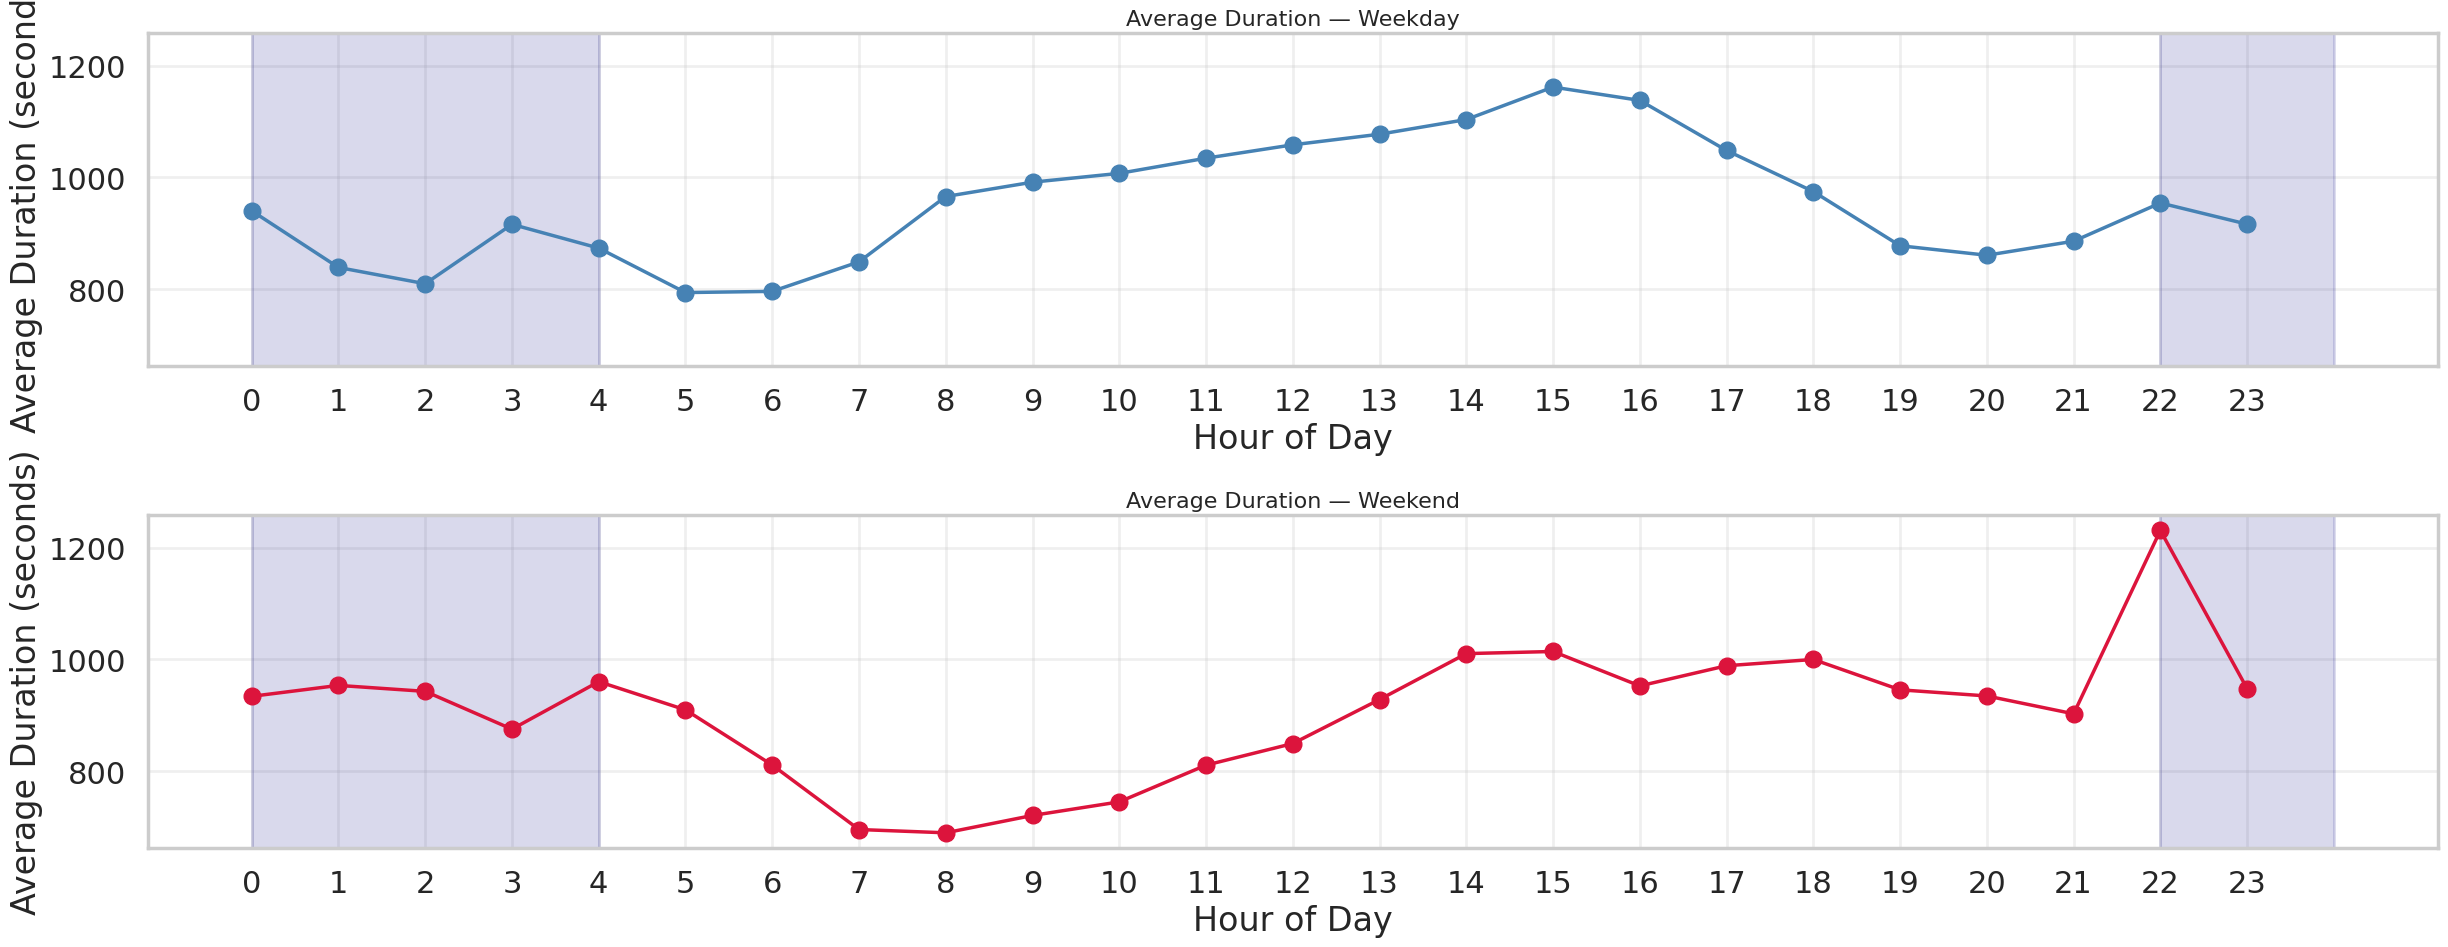

In [46]:
# ─── Hour × weekend aggregation ───
hour_weekend = (
    df_train
    .groupBy("is_weekend", "pickup_hour")
    .agg(
        F.mean("trip_duration").alias("avg_duration"),
        F.count("*").alias("trips")
    )
    .orderBy("is_weekend", "pickup_hour")
)

hour_weekend_pd = hour_weekend.toPandas()

# ─── Two subplots ───
fig, axes = plt.subplots(2, 1, figsize=(25, 10), sharey=True)

for i, (is_wknd, label) in enumerate([(0, "Weekday"), (1, "Weekend")]):
    subset = hour_weekend_pd[hour_weekend_pd["is_weekend"] == is_wknd]
    axes[i].plot(
        subset["pickup_hour"],
        subset["avg_duration"],
        marker='o', linewidth=2.5, color='steelblue' if is_wknd==0 else 'crimson'
    )
    axes[i].set_title(f"Average Duration — {label}", fontsize=16)
    axes[i].set_xlabel("Hour of Day")
    axes[i].set_ylabel("Average Duration (seconds)")
    axes[i].set_xticks(range(24))
    axes[i].grid(True, alpha=0.3)
    axes[i].axvspan(22, 24, alpha=0.15, color='navy')
    axes[i].axvspan(0, 4, alpha=0.15, color='navy')

plt.tight_layout()
plt.show()

* **Weekday Congestion Curve:** Weekday average trip durations build steadily into a sustained afternoon peak around 15:00–16:00, reflecting persistent heavy urban traffic.


* **Weekend Nightlife Anomaly:** Weekend patterns display an extreme duration spike shooting past 1,200 seconds at 22:00, capturing severe late-night weekend bottlenecks.


* **Feature Engineering Implications:** The striking structural divergence between weekday mid-afternoon delays and weekend night spikes underscores the need for granular day-type and hour interaction variables.

In [47]:
# ─── Monthly statistics ───
monthly_stats = (
    df_train
    .groupBy("pickup_month")
    .agg(
        F.count("*").alias("trip_count"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance_km"),
        F.mean("is_weekend").alias("weekend_ratio")
    )
    .orderBy("pickup_month")
)

monthly_stats.show(truncate=False)

+------------+----------+------------------+---------------+------------------+-------------------+
|pickup_month|trip_count|avg_duration      |median_duration|avg_distance_km   |weekend_ratio      |
+------------+----------+------------------+---------------+------------------+-------------------+
|1           |228494    |921.977242290826  |630            |3.3650919486531454|0.2936313426173116 |
|2           |237116    |921.3964220044198 |636            |3.3129276869039987|0.28600347509235985|
|3           |254958    |937.5906423803136 |654            |3.4244337377905536|0.2652240761223417 |
|4           |250389    |963.5756722539728 |675            |3.4243191606604486|0.3103490968053708 |
|5           |247217    |999.2343002301621 |690            |3.532445558946668 |0.2937176650473066 |
|6           |233019    |1012.7643325222407|696            |3.5107634074348755|0.2629914298834001 |
+------------+----------+------------------+---------------+------------------+-------------------+


* **Seasonal Duration Inflation:** Average trip durations steadily climb from January (~922 s) to June (~1,013 s), reflecting cumulative seasonal increases in traffic density and congestion over the half-year period.
* **Spring Demand Peak:** Trip volumes peak during the spring months, reaching a high of 254,958 trips in March, which captures strong seasonal mobility and rider demand.
* **Macro-Trend Feature Value:** `pickup_month` provides a reliable temporal feature for tree-based models to capture broader seasonal shifts in traffic speeds and travel patterns.

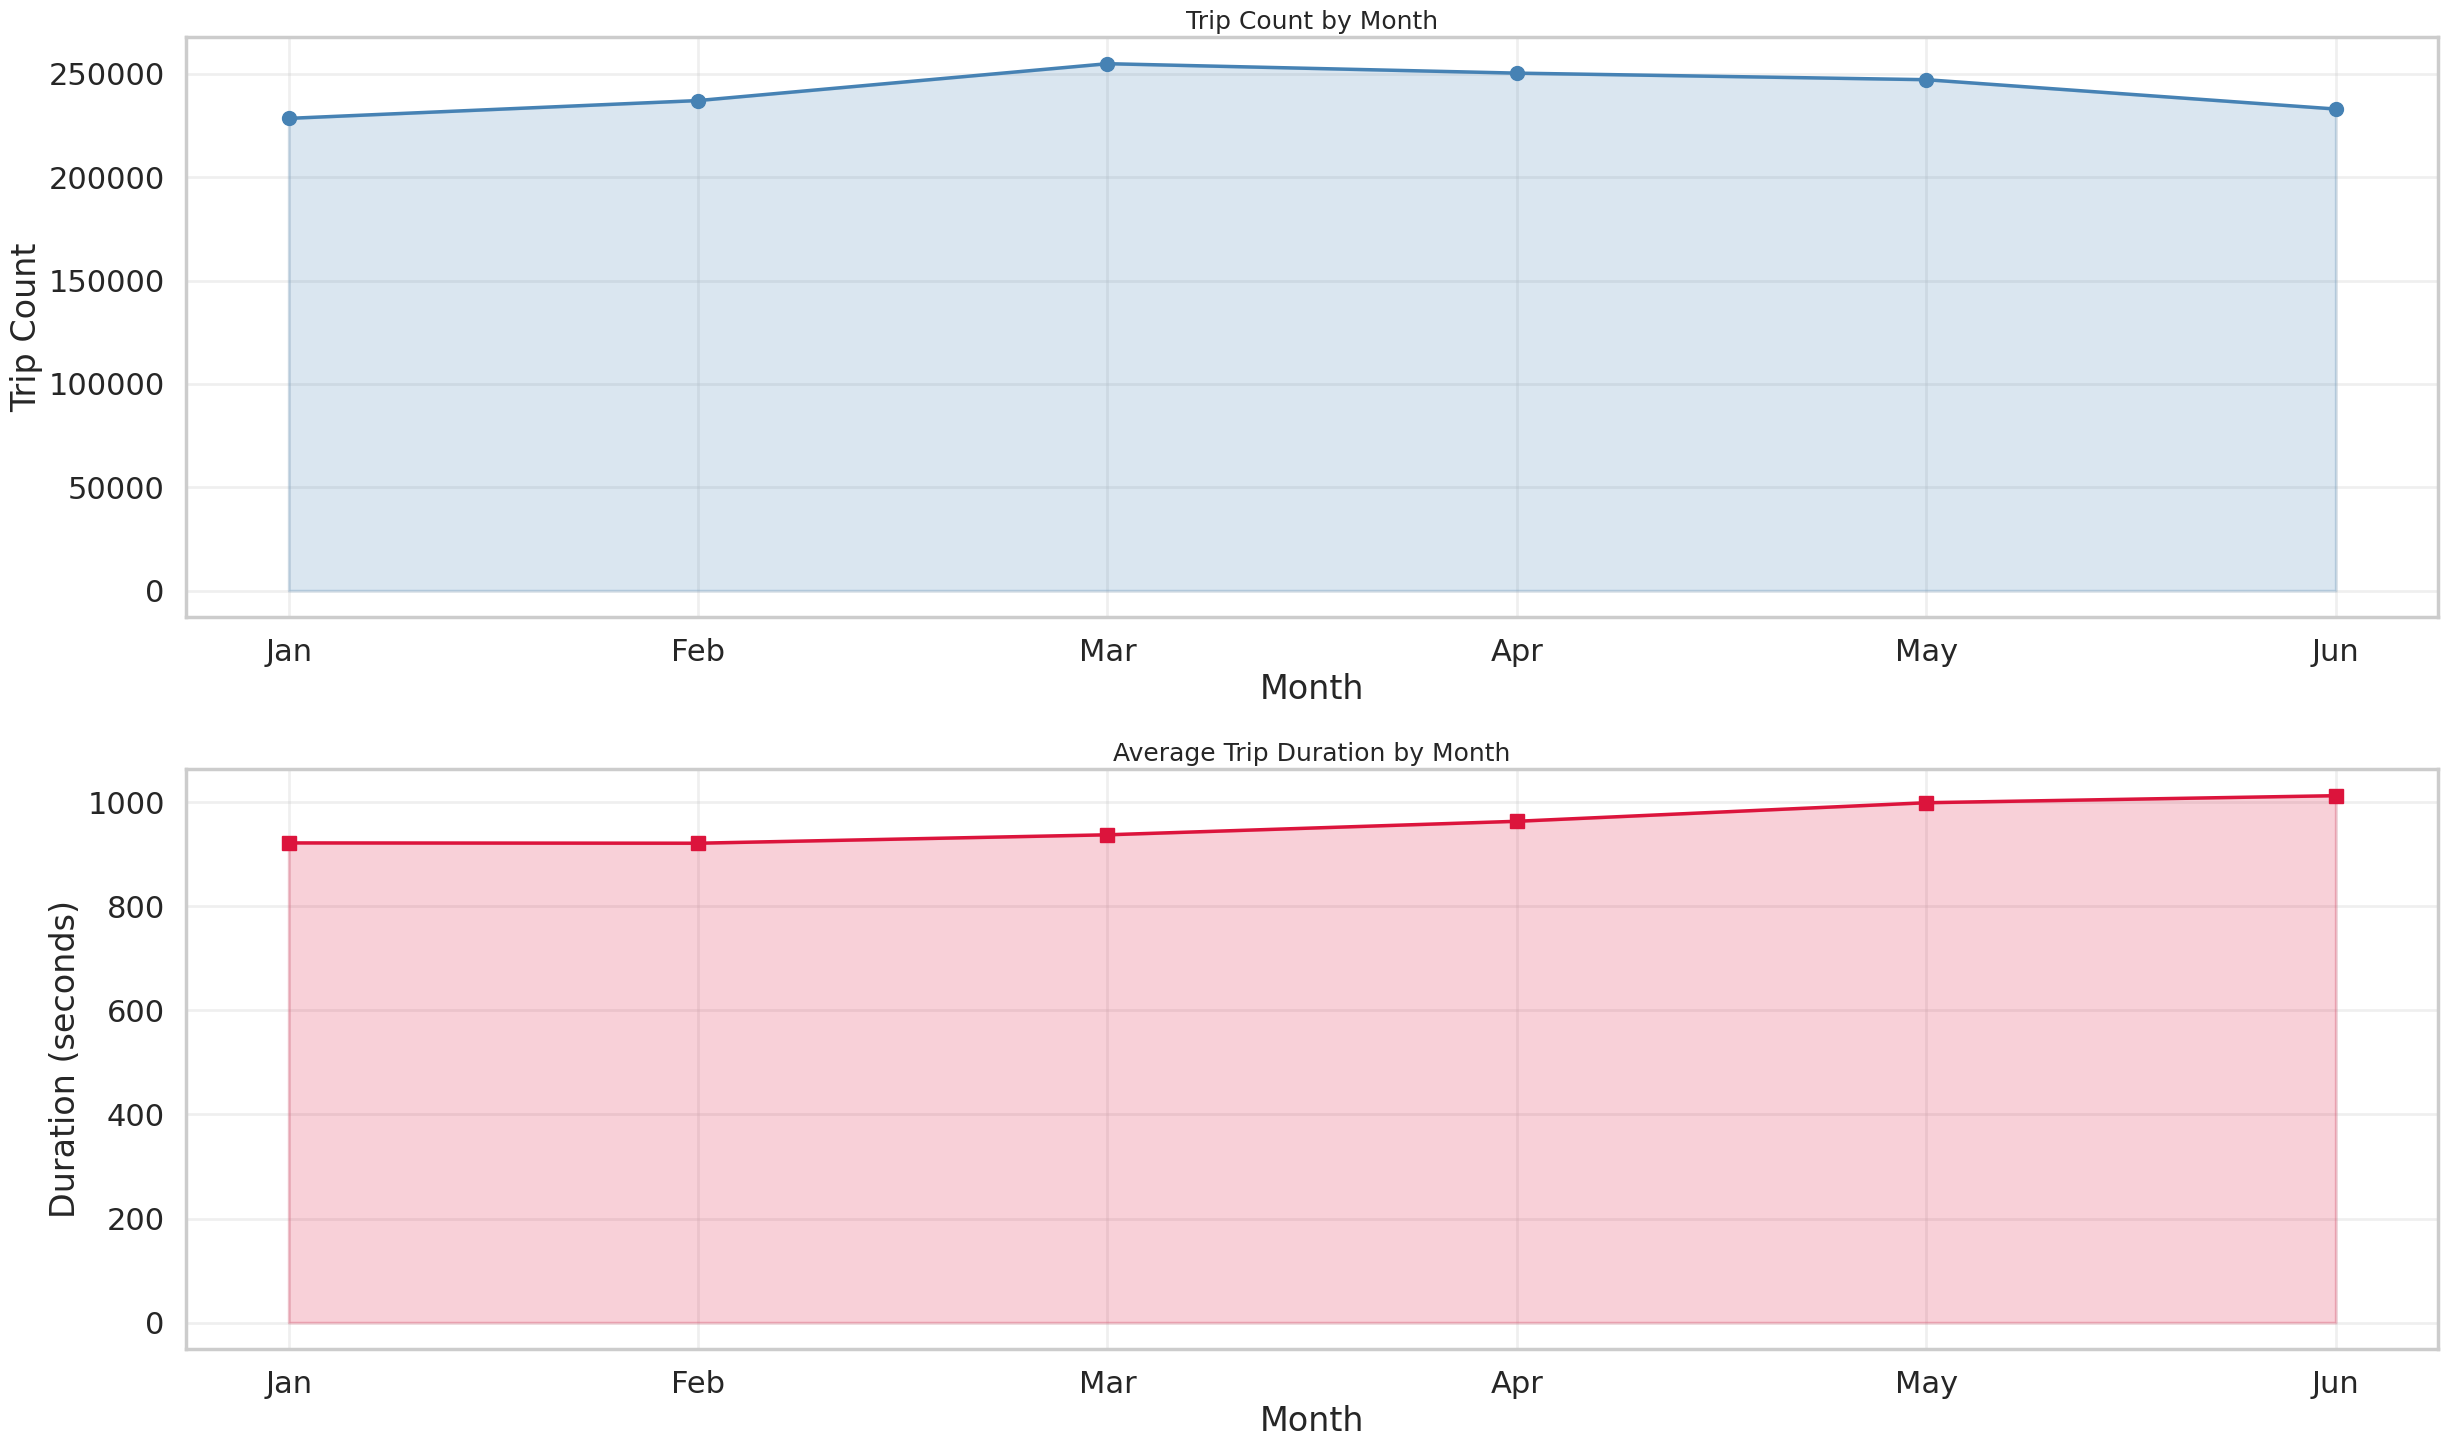

In [48]:
monthly_pd = monthly_stats.toPandas()
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
monthly_pd['month_name'] = monthly_pd['pickup_month'].map(
    lambda x: month_names[x-1]
)

fig, axes = plt.subplots(2, 1, figsize=(25, 15))

# ─── Chart 1: Trip count ───
axes[0].plot(
    monthly_pd['month_name'],
    monthly_pd['trip_count'],
    marker='o', linewidth=2.5, color='steelblue', markersize=10
)
axes[0].fill_between(
    range(len(monthly_pd)),
    monthly_pd['trip_count'],
    alpha=0.2, color='steelblue'
)
axes[0].set_title("Trip Count by Month", fontsize=18)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Trip Count")
axes[0].grid(True, alpha=0.3)

# ─── Chart 2: Average duration ───
axes[1].plot(
    monthly_pd['month_name'],
    monthly_pd['avg_duration'],
    marker='s', linewidth=2.5, color='crimson', markersize=10
)
axes[1].fill_between(
    range(len(monthly_pd)),
    monthly_pd['avg_duration'],
    alpha=0.2, color='crimson'
)
axes[1].set_title("Average Trip Duration by Month", fontsize=18)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Duration (seconds)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

* **Spring Volume Peak:** Trip counts reach their highest point during March before experiencing a gradual decline heading into June.


* **Upward Duration Trend:** Average trip durations demonstrate a steady, cumulative climb from January through June, rising from roughly 920 seconds to over 1,000 seconds.


* **Seasonal Macro-Signal:** The divergence between peak spring demand and continuously increasing travel times highlights important seasonal congestion dynamics that should be captured via temporal features.

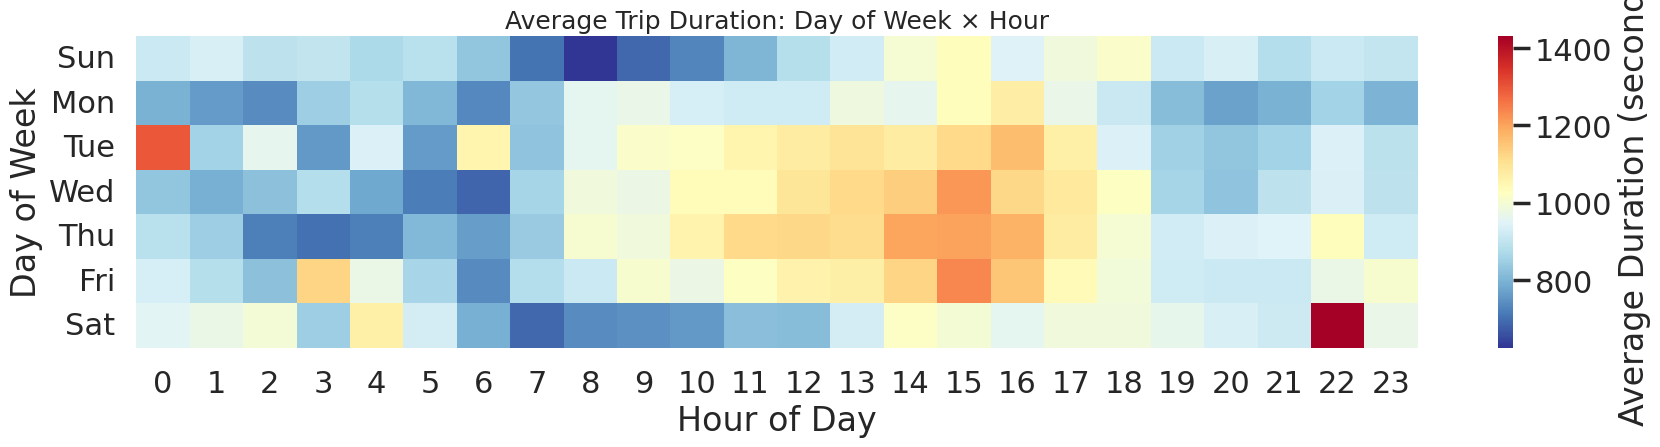

In [49]:
# ─── Aggregate ───
day_hour = (
    df_train
    .groupBy("pickup_dayofweek", "pickup_hour")
    .agg(F.mean("trip_duration").alias("avg_duration"))
    .orderBy("pickup_dayofweek", "pickup_hour")
)

# ─── Pivot ───
pivot = day_hour.toPandas().pivot(
    index="pickup_dayofweek",
    columns="pickup_hour",
    values="avg_duration"
)

# ─── Plot ───
plt.figure(figsize=(18, 5))
sns.heatmap(
    pivot,
    cmap="RdYlBu_r",
    annot=False,
    cbar_kws={"label": "Average Duration (seconds)"}
)
plt.title("Average Trip Duration: Day of Week × Hour", fontsize=18)
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.yticks(
    ticks=[i+0.5 for i in range(7)],
    labels=['Sun','Mon','Tue','Wed','Thu','Fri','Sat'],
    rotation=0
)
plt.tight_layout()
plt.show()

* **Mid-Week Afternoon Bottlenecks:** Wednesday through Friday afternoons (14:00–16:00) exhibit sustained high average durations, highlighting recurring mid-week urban traffic congestion peaks.


* **Isolated Extreme Anomalies:** Sharp, localized duration spikes appear at atypical times—such as Tuesday at midnight and Saturday at 22:00—signaling potential outlier logs or severe localized traffic events.


* **Feature Value:** The complex, non-linear interaction between day of week and hour strongly supports creating a cross-feature matrix to help tree-based models capture these specific traffic dynamics.

In [50]:
# ─── Compare distances ───
distance_comparison = (
    df_train
    .groupBy("is_weekend", "is_late_night")
    .agg(
        F.mean("haversine_km").alias("avg_distance"),
        F.mean("trip_duration").alias("avg_duration"),
        F.count("*").alias("trips")
    )
    .orderBy("is_weekend", "is_late_night")
)

distance_comparison.show(truncate=False)

+----------+-------------+------------------+-----------------+------+
|is_weekend|is_late_night|avg_distance      |avg_duration     |trips |
+----------+-------------+------------------+-----------------+------+
|0         |0            |3.2523124492155806|984.8588298650745|854175|
|0         |1            |4.086455493895465 |916.6945200835493|182886|
|1         |0            |3.404010718578278 |901.6406913363828|292072|
|1         |1            |3.7415170914552682|985.1199328199247|122060|
+----------+-------------+------------------+-----------------+------+



* **Off-Peak Velocity:** Weekday late-night trips (`is_weekend=0, is_late_night=1`) achieve high efficiency, covering longer distances ($\approx 4.09$ km) more quickly due to uninhibited road conditions.
* **Nightlife Bottlenecks:** Weekend late-night trips (`is_weekend=1, is_late_night=1`) experience inflated durations ($985$ s) relative to their distance, capturing heavy weekend entertainment and congestion patterns.
* **Interaction Utility:** This clear divergence confirms that crossing weekend flags with late-night indicators provides essential non-linear signals for tree-based models to accurately predict travel time.

2

In [51]:
from pyspark.sql import functions as F
import time

start = time.time()

# ─── Round coordinates to 2 decimal places (~1.1 km grid) ───
df_train = (
    df_train
    .withColumn("pickup_lon_r2", F.round("pickup_longitude", 2))
    .withColumn("pickup_lat_r2", F.round("pickup_latitude", 2))
    .withColumn("dropoff_lon_r2", F.round("dropoff_longitude", 2))
    .withColumn("dropoff_lat_r2", F.round("dropoff_latitude", 2))
)

# ─── Also create finer grid (3 decimals, ~110m) ───
df_train = (
    df_train
    .withColumn("pickup_lon_r3", F.round("pickup_longitude", 3))
    .withColumn("pickup_lat_r3", F.round("pickup_latitude", 3))
)

print(f"⏱️ {time.time()-start:.2f}s")

⏱️ 0.05s


In [52]:
# ─── Top 20 pickup hotspots ───
top_pickup = (
    df_train
    .groupBy("pickup_lon_r2", "pickup_lat_r2")
    .agg(F.count("*").alias("pickup_count"))
    .orderBy(F.desc("pickup_count"))
    .limit(20)
)

top_pickup.show(20, truncate=False)

+-------------+-------------+------------+
|pickup_lon_r2|pickup_lat_r2|pickup_count|
+-------------+-------------+------------+
|-73.97       |40.76        |89989       |
|-73.99       |40.75        |89835       |
|-73.98       |40.76        |77523       |
|-73.98       |40.75        |72402       |
|-73.99       |40.74        |65662       |
|-73.99       |40.76        |65505       |
|-73.96       |40.77        |51281       |
|-73.99       |40.73        |51045       |
|-73.98       |40.77        |47580       |
|-74.0        |40.73        |44272       |
|-74.0        |40.74        |43797       |
|-73.98       |40.74        |41321       |
|-73.96       |40.78        |38999       |
|-73.95       |40.78        |37690       |
|-73.98       |40.78        |35976       |
|-73.99       |40.72        |34064       |
|-73.97       |40.75        |32140       |
|-73.95       |40.77        |27858       |
|-74.0        |40.72        |27695       |
|-73.97       |40.79        |25518       |
+----------

In [53]:
# ─── Top 20 dropoff hotspots ───
top_dropoff = (
    df_train
    .groupBy("dropoff_lon_r2", "dropoff_lat_r2")
    .agg(F.count("*").alias("dropoff_count"))
    .orderBy(F.desc("dropoff_count"))
    .limit(20)
)

top_dropoff.show(20, truncate=False)

+--------------+--------------+-------------+
|dropoff_lon_r2|dropoff_lat_r2|dropoff_count|
+--------------+--------------+-------------+
|-73.98        |40.76         |77945        |
|-73.97        |40.76         |76994        |
|-73.99        |40.75         |74540        |
|-73.98        |40.75         |69780        |
|-73.99        |40.74         |55013        |
|-73.99        |40.76         |52614        |
|-73.96        |40.77         |50955        |
|-73.99        |40.73         |40834        |
|-73.98        |40.74         |40340        |
|-73.98        |40.77         |38914        |
|-73.95        |40.78         |37664        |
|-73.96        |40.78         |37198        |
|-74.0         |40.73         |36236        |
|-74.0         |40.74         |35492        |
|-73.98        |40.78         |34056        |
|-73.97        |40.75         |32140        |
|-73.95        |40.77         |27514        |
|-74.01        |40.71         |26672        |
|-74.0         |40.72         |258

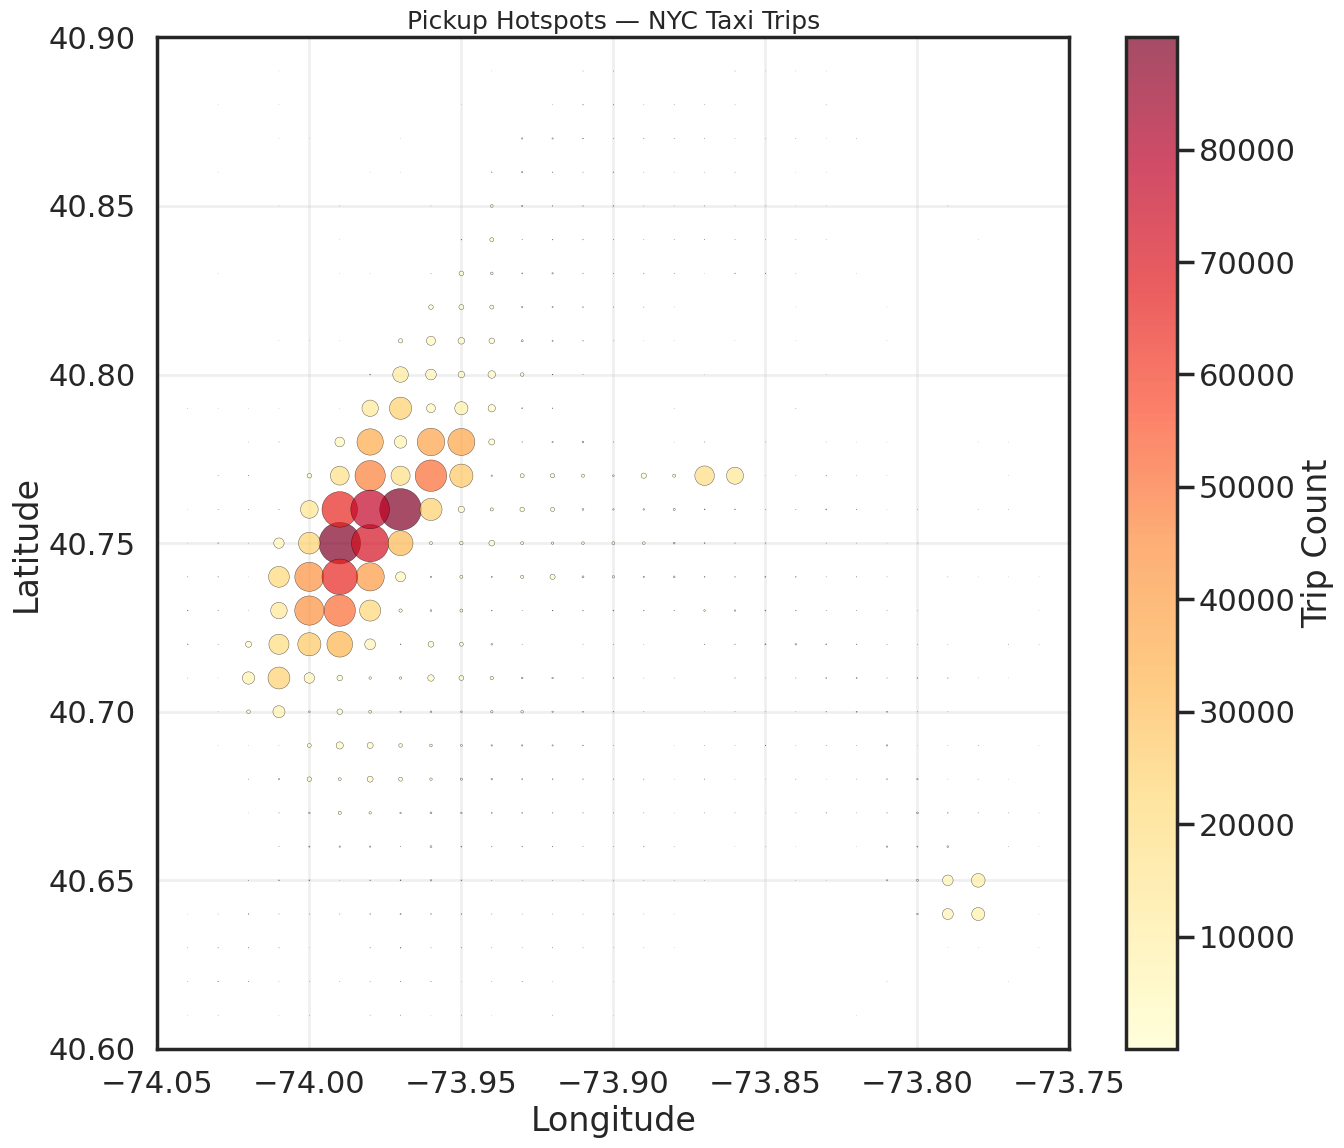

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# ─── Aggregate all pickups ───
pickup_map = (
    df_train
    .groupBy("pickup_lon_r2", "pickup_lat_r2")
    .agg(F.count("*").alias("count"))
    .toPandas()
)

sns.set_theme(style="white", context="poster")
plt.figure(figsize=(14, 12))

scatter = plt.scatter(
    pickup_map["pickup_lon_r2"],
    pickup_map["pickup_lat_r2"],
    s=pickup_map["count"] / 100,   # size proportional to count
    c=pickup_map["count"],
    cmap="YlOrRd",
    alpha=0.7,
    edgecolors="black",
    linewidth=0.3
)

plt.colorbar(scatter, label="Trip Count")
plt.title("Pickup Hotspots — NYC Taxi Trips", fontsize=18)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-74.05, -73.75)
plt.ylim(40.60, 40.90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

we round the lon and lat to count the dropoff and show it in this map 

In [55]:
# ─── Define airport bounding boxes ───
JFK_BOUNDS = {"lon": (-73.82, -73.74), "lat": (40.62, 40.68)}
LGA_BOUNDS = {"lon": (-73.90, -73.84), "lat": (40.75, 40.80)}

# ─── Flag airport pickups ───
df_train = (
    df_train
    .withColumn(
        "is_jfk_pickup",
        F.when(
            (F.col("pickup_longitude").between(*JFK_BOUNDS["lon"])) &
            (F.col("pickup_latitude").between(*JFK_BOUNDS["lat"])), 1
        ).otherwise(0)
    )
    .withColumn(
        "is_lga_pickup",
        F.when(
            (F.col("pickup_longitude").between(*LGA_BOUNDS["lon"])) &
            (F.col("pickup_latitude").between(*LGA_BOUNDS["lat"])), 1
        ).otherwise(0)
    )
)

# ─── Stats for airport trips ───
airport_stats = (
    df_train
    .withColumn(
        "trip_type",
        F.when(F.col("is_jfk_pickup") == 1, "JFK_pickup")
        .when(F.col("is_lga_pickup") == 1, "LGA_pickup")
        .otherwise("other")
    )
    .groupBy("trip_type")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.mean("haversine_km").alias("avg_distance_km"),
        F.mean("passenger_count").alias("avg_passengers")
    )
    .orderBy(F.desc("trips"))
)

airport_stats.show(truncate=False)

+----------+-------+------------------+------------------+------------------+
|trip_type |trips  |avg_duration      |avg_distance_km   |avg_passengers    |
+----------+-------+------------------+------------------+------------------+
|other     |1382209|892.1462231833247 |2.9435979102021026|1.66196212005565  |
|LGA_pickup|37386  |1913.171802278928 |9.568160943567854 |1.7156154710319371|
|JFK_pickup|31598  |2779.3450218368253|17.403711995890255|1.717418823976201 |
+----------+-------+------------------+------------------+------------------+



* **Airport Trip Impact:** Airport pickups from JFK and LGA feature drastically longer durations ($\approx 2,779$ s and $1,913$ s) and distances ($\approx 17.4$ km and $9.57$ km) compared to local city trips, reflecting major long-haul routes.
* **Volume Dominance:** Regular city trips (`other`) comprise the vast majority of the dataset ($1,382,209$ trips) with a much shorter average distance ($\approx 2.94$ km).
* **Feature Engineering Value:** `trip_type` is an exceptionally powerful categorical predictor that directly separates long-distance airport transit from standard urban micro-mobility.

Part 2: Distance vs Duration Relationship

In [56]:
# ─── Create distance bins (1 km each) ───
df_train = df_train.withColumn(
    "distance_bin",
    F.floor(F.col("haversine_km")).cast("int")
)

# ─── Aggregate by distance bin ───
distance_duration = (
    df_train
    .filter(F.col("distance_bin") <= 30)   # cap at 30 km
    .groupBy("distance_bin")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.expr("percentile_approx(trip_duration, 0.9)").alias("p90_duration")
    )
    .orderBy("distance_bin")
)

distance_duration.show(31, truncate=False)

+------------+------+------------------+---------------+------------+
|distance_bin|trips |avg_duration      |median_duration|p90_duration|
+------------+------+------------------+---------------+------------+
|0           |239889|429.0997836499381 |268            |574         |
|1           |451218|645.3959593810531 |476            |882         |
|2           |265582|877.9441679029452 |708            |1195        |
|3           |145239|1098.3133731298067|891            |1475        |
|4           |88014 |1250.6737905333243|1052           |1699        |
|5           |58339 |1415.34333807573  |1183           |1865        |
|6           |40441 |1502.6356915011993|1281           |1998        |
|7           |26808 |1614.6043718293047|1361           |2113        |
|8           |23074 |1696.4965762329896|1485           |2346        |
|9           |24787 |1910.4535845402831|1647           |2690        |
|10          |15981 |2046.281396658532 |1712           |2841        |
|11          |9171  

* **Volume Concentration:** Trip counts are heavily front-loaded in lower distance bins (0 through 5), providing robust statistical power for short-to-medium urban trips while suffering from severe sample sparsity in bins 25 and above.
* **Monotonic Scaling & Tail Noise:** Durations scale predictably with distance up to bin 20, after which low sample counts (e.g., under 100 trips) introduce high volatility, erratic averages, and plateauing anomalies.
* **Widening Dispersion:** The expanding spread between median durations and 90th percentile (`p90_duration`) values across higher distance bins highlights increasing travel-time variance and unpredictable traffic bottlenecks on longer routes.

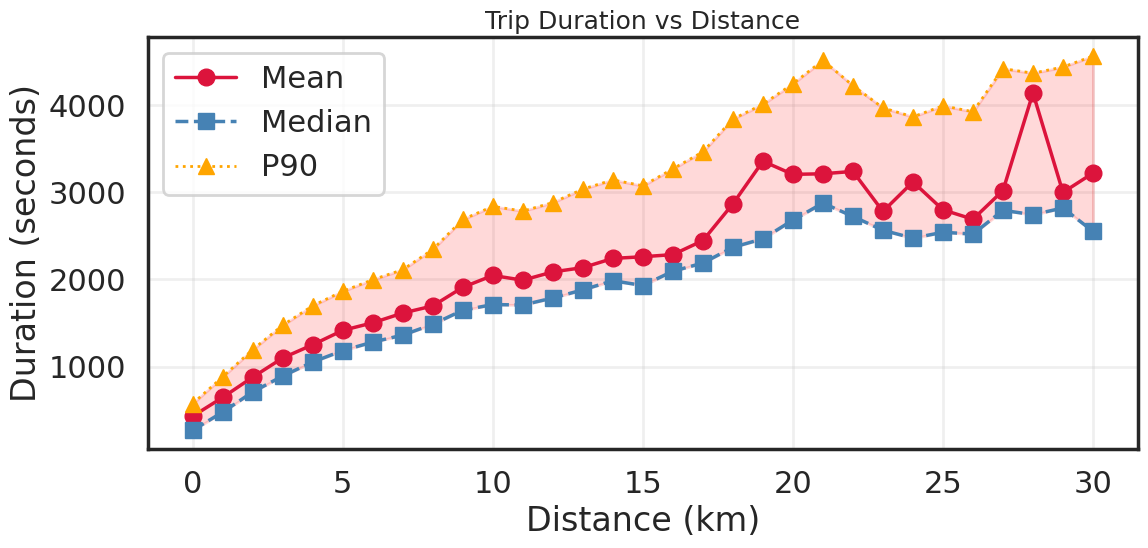

In [57]:
distance_pd = distance_duration.toPandas()

plt.figure(figsize=(12, 6))
plt.plot(
    distance_pd["distance_bin"],
    distance_pd["avg_duration"],
    marker='o', linewidth=2.5, color='crimson', label='Mean'
)
plt.plot(
    distance_pd["distance_bin"],
    distance_pd["median_duration"],
    marker='s', linewidth=2.5, color='steelblue', 
    linestyle='--', label='Median'
)
plt.plot(
    distance_pd["distance_bin"],
    distance_pd["p90_duration"],
    marker='^', linewidth=2, color='orange', 
    linestyle=':', label='P90'
)
plt.fill_between(
    distance_pd["distance_bin"],
    distance_pd["median_duration"],
    distance_pd["p90_duration"],
    alpha=0.15, color='red'
)
plt.title("Trip Duration vs Distance", fontsize=18)
plt.xlabel("Distance (km)")
plt.ylabel("Duration (seconds)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

* Duration scales predictably with distance up to roughly 21 km, after which the median flattens while the mean exhibits erratic volatility and extreme spikes (e.g., near 28 km).


* The widening shaded gap between the median and the 90th percentile (P90) at higher distances underscores escalating travel-time variance and congestion unpredictability on long-haul routes.


* The erratic fluctuations past 25 km signal severe sample sparsity, indicating that downstream models will require distance caps or robust loss handling to avoid noise distortion.

In [58]:
# ─── Compute speed ───
speed_analysis = (
    distance_duration
    .withColumn(
        "avg_speed_kmh",
        (F.col("distance_bin") / (F.col("avg_duration") / 3600))
    )
    .select("distance_bin", "trips", "avg_duration", "avg_speed_kmh")
    .orderBy("distance_bin")
)

speed_analysis.show(31, truncate=False)

+------------+------+------------------+------------------+
|distance_bin|trips |avg_duration      |avg_speed_kmh     |
+------------+------+------------------+------------------+
|0           |239889|429.0997836499381 |0.0               |
|1           |451218|645.3959593810531 |5.577971085304699 |
|2           |265582|877.9441679029452 |8.200977081717962 |
|3           |145239|1098.3133731298067|9.833259126421998 |
|4           |88014 |1250.6737905333243|11.513793691846228|
|5           |58339 |1415.34333807573  |12.717762196466344|
|6           |40441 |1502.6356915011993|14.374741743569693|
|7           |26808 |1614.6043718293047|15.607538564663402|
|8           |23074 |1696.4965762329896|16.976161581150595|
|9           |24787 |1910.4535845402831|16.95932330530631 |
|10          |15981 |2046.281396658532 |17.59288827958172 |
|11          |9171  |1991.9992367244574|19.879525689536024|
|12          |6740  |2087.4541543026708|20.69506528368824 |
|13          |6561  |2136.4538942234417|

* **Zero-Speed Micro-Trips:** Distance bin $0$ registers an average speed of $0.0\text{ km/h}$ across nearly 240,000 trips, highlighting stationary or ultra-short records that likely require filtering or dedicated data hygiene rules.
* **Speed Progression & Infrastructure Shift:** Average speeds scale upward progressively from $\approx 5.6\text{ km/h}$ in bin $1$ to peak near $\approx 34.8\text{ km/h}$ in sparse higher bins, cleanly capturing the transition from congested local grid streets to arterial highways and expressways.
* **Tail Sparsity & Volatility:** Trip volumes plummet drastically past bin $22$ (dropping below 1,000 samples), introducing erratic speed fluctuations that reinforce the need for distance capping or robust tree-based split handling to prevent overfitting on noise.

In [59]:
# ─── Distance bin × rush hour ───
distance_rush = (
    df_train
    .filter(F.col("distance_bin").between(0, 15))
    .groupBy("distance_bin", "is_rush_hour")
    .agg(F.mean("trip_duration").alias("avg_duration"))
    .orderBy("distance_bin", "is_rush_hour")
)

distance_rush.show(32, truncate=False)

+------------+------------+------------------+
|distance_bin|is_rush_hour|avg_duration      |
+------------+------------+------------------+
|0           |0           |429.79493600445187|
|0           |1           |427.6613441830116 |
|1           |0           |651.5432554135488 |
|1           |1           |632.9520502955804 |
|2           |0           |870.6137274990637 |
|2           |1           |893.780933907704  |
|3           |0           |1077.8500187921588|
|3           |1           |1145.1936646047175|
|4           |0           |1215.18848448499  |
|4           |1           |1341.8596284879948|
|5           |0           |1408.291514290373 |
|5           |1           |1434.9916926272067|
|6           |0           |1465.9033960532354|
|6           |1           |1615.4243583291393|
|7           |0           |1597.0567407189446|
|7           |1           |1670.3646563814866|
|8           |0           |1651.553073583181 |
|8           |1           |1837.733752244165 |
|9           

* **Short-Distance Anomaly:** For distance bins $0$ and $1$, non-rush hour average durations are slightly higher than or comparable to rush hour durations (e.g., bin $0$: $429.8$ s vs. $427.7$ s; bin $1$: $651.5$ s vs. $633.0$ s), indicating that traffic congestion has minimal impact on ultra-short trips.
* **Consistent Rush-Hour Penalty:** Starting from distance bin $2$ and above, rush-hour average durations (`is_rush_hour=1`) consistently exceed non-rush hour durations (`is_rush_hour=0`), properly reflecting urban traffic slowdowns.
* **Widening Time Gap:** The absolute duration difference between rush-hour and non-rush hour trips expands significantly as distance increases (growing from a minor difference in bin $2$ to a $353.5$-second gap by bin $12$), demonstrating a compounding congestion effect on longer routes.

In [60]:
# ─── Define Manhattan bounding box ───
MANHATTAN = {"lon": (-74.02, -73.90), "lat": (40.70, 40.88)}

df_train = df_train.withColumn(
    "is_manhattan",
    F.when(
        (F.col("pickup_longitude").between(*MANHATTAN["lon"])) &
        (F.col("pickup_latitude").between(*MANHATTAN["lat"])), 1
    ).otherwise(0)
)

# ─── Speed by zone × distance bin ───
zone_speed = (
    df_train
    .filter(F.col("distance_bin").between(1, 10))
    .groupBy("is_manhattan", "distance_bin")
    .agg(
        F.mean("trip_duration").alias("avg_duration"),
        F.mean("haversine_km").alias("avg_distance")
    )
    .withColumn(
        "avg_speed_kmh",
        F.col("avg_distance") / (F.col("avg_duration") / 3600)
    )
    .orderBy("is_manhattan", "distance_bin")
)

zone_speed.show(truncate=False)

+------------+------------+------------------+------------------+------------------+
|is_manhattan|distance_bin|avg_duration      |avg_distance      |avg_speed_kmh     |
+------------+------------+------------------+------------------+------------------+
|0           |1           |561.0745440126883 |1.4790412736074139|9.489912956853518 |
|0           |2           |827.3508643778914 |2.5010132974312986|10.882502525120069|
|0           |3           |863.9432826362485 |3.484546610119705 |14.519897368902367|
|0           |4           |1018.8953529620433|4.486258727848036 |15.851020787661383|
|0           |5           |1146.6485251350227|5.496158914104417 |17.25565564081286 |
|0           |6           |1421.552953156823 |6.518698821537391 |16.50822482934671 |
|0           |7           |1464.215565796211 |7.518489702280679 |18.485367565049884|
|0           |8           |1729.6684483046602|8.56564019287292  |17.827870262978326|
|0           |9           |2050.8255813953488|9.50935209837161  |

### Manhattan vs. Non-Manhattan Spatial Dynamics

* **Severe Manhattan Congestion Tax:** For identical distance tiers, trips inside Manhattan (`is_manhattan=1`) incur a massive duration penalty compared to non-Manhattan routes (`is_manhattan=0`). For instance, in distance bin 3 ($\approx 3.45\text{ km}$), Manhattan trips average $1,103.5$ seconds ($18.4$ minutes) compared to just $863.9$ seconds ($14.4$ minutes) outside Manhattan.
* **Lower Micro-Mobility Speeds:** In the lowest distance bins ($1$ and $2$), non-Manhattan average speeds outperform Manhattan speeds (e.g., bin $1$: $9.49\text{ km/h}$ vs. $8.18\text{ km/h}$), capturing the intense stop-and-go gridlock and traffic signal density of core Manhattan streets.
* **Speed Convergence on Longer Routes:** As distance bins increase toward bin $10$, average speeds across both regions converge and rise (reaching $16.69\text{ km/h}$ for non-Manhattan and $19.84\text{ km/h}$ for Manhattan), reflecting the transition to arterial highways, FDR drive, or expressways.



In [61]:
# 1. Airport flag
df_train = df_train.withColumn(
    "is_airport_pickup",
    F.when(
        ((F.col("pickup_latitude").between(40.62, 40.68)) & 
         (F.col("pickup_longitude").between(-73.82, -73.74))) |
        ((F.col("pickup_latitude").between(40.75, 40.80)) &
         (F.col("pickup_longitude").between(-73.90, -73.84))),
        1
    ).otherwise(0)
)

# 2. Manhattan flag
df_train = df_train.withColumn(
    "is_manhattan",
    F.when(
        (F.col("pickup_longitude").between(-74.02, -73.90)) &
        (F.col("pickup_latitude").between(40.70, 40.88)),
        1
    ).otherwise(0)
)

# 3. Short + rush hour interaction
df_train = df_train.withColumn(
    "slow_trip_indicator",
    F.when(
        (F.col("is_rush_hour") == 1) & (F.col("haversine_km") < 3),
        1
    ).otherwise(0)
)

passenger count analysis

In [62]:
from pyspark.sql import functions as F
import time

start = time.time()

# ─── Basic passenger count stats ───
passenger_stats = (
    df_train
    .groupBy("passenger_count")
    .agg(
        F.count("*").alias("trip_count"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.mean("haversine_km").alias("avg_distance_km"),
        F.mean("is_rush_hour").alias("rush_hour_ratio"),
        F.mean("is_weekend").alias("weekend_ratio")
    )
    .orderBy("passenger_count")
)

passenger_stats.show(truncate=False)
print(f"⏱️ {time.time()-start:.2f}s")

+---------------+----------+------------------+---------------+------------------+-------------------+-------------------+
|passenger_count|trip_count|avg_duration      |median_duration|avg_distance_km   |rush_hour_ratio    |weekend_ratio      |
+---------------+----------+------------------+---------------+------------------+-------------------+-------------------+
|0              |52        |1979.2884615384614|22             |1.438792692279864 |0.19230769230769232|0.40384615384615385|
|1              |1028194   |930.4240474073958 |655            |3.372457080478774 |0.31344960192337246|0.27106071422319133|
|2              |209289    |1005.8659795784777|690            |3.63764437632943  |0.2879176640912805 |0.3273846212653317 |
|3              |59639     |1026.4081725045692|688            |3.5143355409235215|0.28717785341806534|0.3382015124331394 |
|4              |28234     |1054.1960048168874|698            |3.608576922431742 |0.2742084012183892 |0.35602465112984344|
|5              

* **Zero-Passenger Anomalies:** Passenger count $0$ records an extremely tiny sample size ($52$ trips) with erratic stats—such as an average duration of nearly $1,980$ seconds paired with a median of just $22$ seconds—strongly indicating corrupted logging or test records that need cleaning.
* **Solo-Passenger Volume Dominance:** Single-passenger trips (`passenger_count=1`) overwhelmingly dominate the dataset, accounting for over $1.02$ million trips with the shortest average duration ($930.4$ s) and distance ($3.37$ km).
* **Group Duration Inflation:** Trips with higher passenger counts ($2$ through $6$) exhibit progressively higher average durations (ranging from $1,005$ to $1,069$ seconds) despite comparable distances, capturing subtle differences in trip dynamics or vehicle types for larger groups.

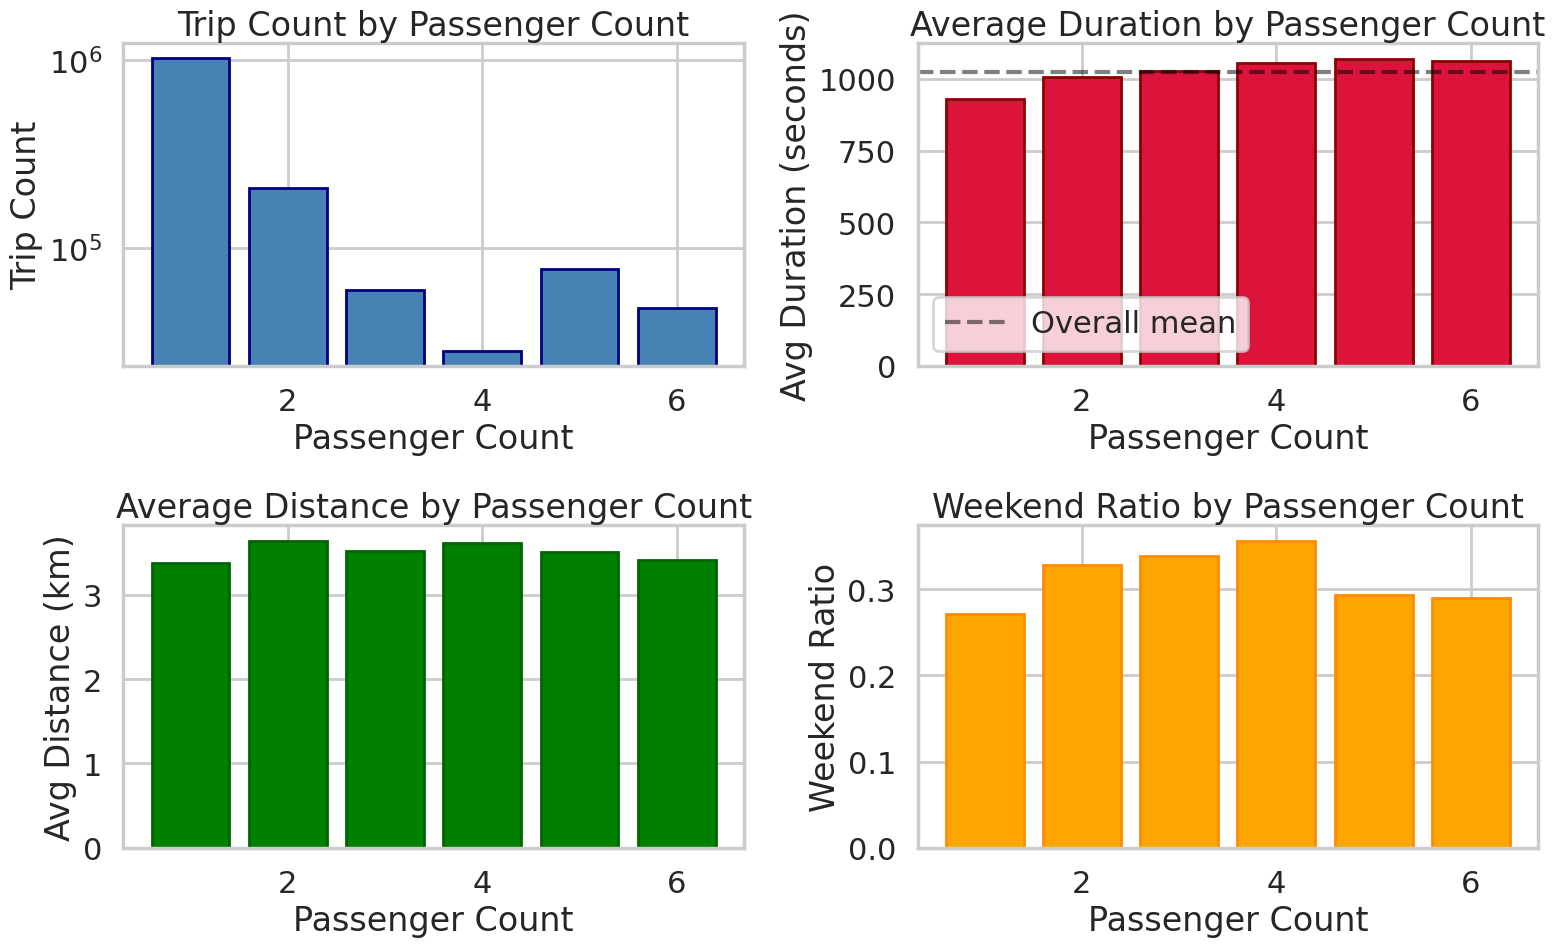

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

passenger_pd = passenger_stats.toPandas()
passenger_pd = passenger_pd[passenger_pd["passenger_count"].between(1, 6)]

sns.set_theme(style="whitegrid", context="poster")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ─── Chart 1: Trip count ───
axes[0, 0].bar(
    passenger_pd["passenger_count"],
    passenger_pd["trip_count"],
    color="steelblue", edgecolor="navy"
)
axes[0, 0].set_title("Trip Count by Passenger Count")
axes[0, 0].set_xlabel("Passenger Count")
axes[0, 0].set_ylabel("Trip Count")
axes[0, 0].set_yscale("log")  # log scale for visibility

# ─── Chart 2: Average duration ───
axes[0, 1].bar(
    passenger_pd["passenger_count"],
    passenger_pd["avg_duration"],
    color="crimson", edgecolor="darkred"
)
axes[0, 1].set_title("Average Duration by Passenger Count")
axes[0, 1].set_xlabel("Passenger Count")
axes[0, 1].set_ylabel("Avg Duration (seconds)")
axes[0, 1].axhline(
    passenger_pd["avg_duration"].mean(),
    color="black", linestyle="--", alpha=0.5, label="Overall mean"
)
axes[0, 1].legend()

# ─── Chart 3: Average distance ───
axes[1, 0].bar(
    passenger_pd["passenger_count"],
    passenger_pd["avg_distance_km"],
    color="green", edgecolor="darkgreen"
)
axes[1, 0].set_title("Average Distance by Passenger Count")
axes[1, 0].set_xlabel("Passenger Count")
axes[1, 0].set_ylabel("Avg Distance (km)")

# ─── Chart 4: Weekend ratio ───
axes[1, 1].bar(
    passenger_pd["passenger_count"],
    passenger_pd["weekend_ratio"],
    color="orange", edgecolor="darkorange"
)
axes[1, 1].set_title("Weekend Ratio by Passenger Count")
axes[1, 1].set_xlabel("Passenger Count")
axes[1, 1].set_ylabel("Weekend Ratio")

plt.tight_layout()
plt.show()

* **Volume Asymmetry:** Single-passenger trips overwhelmingly dominate total dataset volume, exceeding $1,000,000$ records on a log scale, whereas 2-passenger and 5-passenger configurations represent secondary group tiers.


* **Duration Deviations:** Solo rider average durations sit noticeably below the overall dataset mean, while multi-passenger groups (2 through 6 passengers) consistently run above the overall mean duration line.


* **Distance Stability:** Average travel distances remain remarkably uniform across all passenger counts, staying tightly bounded between $3.3\text{ km}$ and $3.7\text{ km}$ regardless of group size.


* **Weekend Propensity:** The ratio of weekend trips is lowest for single-passenger rides at roughly $0.27$, climbing steadily to peak for 4-passenger group rides at approximately $0.35$.



---

### Modeling & Feature Recommendations

* **Categorical Handling:** `passenger_count` should be treated as a categorical or embedding feature rather than a continuous numeric variable, given the nonlinear jump in duration and weekend ratios between solo and group rides.


* **Data Hygiene Check:** The anomalous zero-passenger records identified earlier should be permanently dropped or imputed before model training to prevent skewing tree splits.


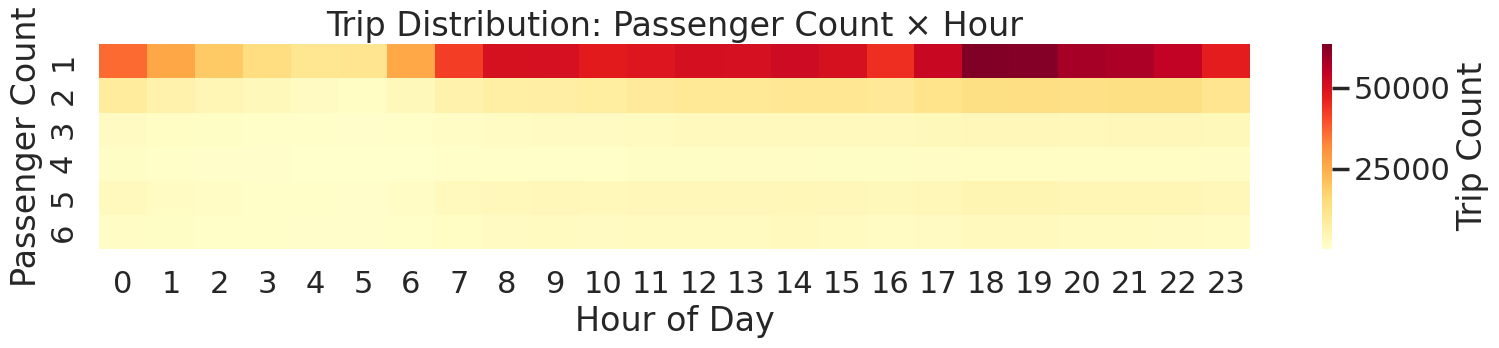

In [64]:
# ─── Hour × passenger_count ───
passenger_hour = (
    df_train
    .filter(F.col("passenger_count").between(1, 6))
    .groupBy("passenger_count", "pickup_hour")
    .agg(F.count("*").alias("trips"))
    .orderBy("passenger_count", "pickup_hour")
)

passenger_hour_pd = passenger_hour.toPandas()

# ─── Heatmap ───
pivot = passenger_hour_pd.pivot(
    index="passenger_count", columns="pickup_hour", values="trips"
).fillna(0)

plt.figure(figsize=(16, 4))
sns.heatmap(
    pivot, cmap="YlOrRd", annot=False,
    cbar_kws={"label": "Trip Count"}
)
plt.title("Trip Distribution: Passenger Count × Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

* **Solo Volume Dominance & Evening Peak:** Single-passenger trips overwhelmingly drive the volume scale, showing an intense surge during late afternoon and evening hours (especially between hours 17 and 20) where trip counts exceed 50,000.


* **Low-Volume Group Uniformity:** Multi-passenger configurations (counts 2 through 6) remain uniformly low and light-yellow across the entire 24-hour cycle, indicating that group travel volume does not experience the same dramatic rush-hour spikes.


* **Macro-Trend Alignment:** The interaction heatmap demonstrates that overall city-wide hourly demand patterns are primarily shaped by solo commuters and travelers, while group rides maintain a much flatter temporal distribution.

In [65]:
# ─── Passenger × weekend ───
passenger_weekend = (
    df_train
    .filter(F.col("passenger_count").between(1, 6))
    .groupBy("passenger_count", "is_weekend")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration")
    )
    .orderBy("passenger_count", "is_weekend")
)

passenger_weekend.show(truncate=False)

+---------------+----------+------+------------------+
|passenger_count|is_weekend|trips |avg_duration      |
+---------------+----------+------+------------------+
|1              |0         |749491|942.3668636447936 |
|1              |1         |278703|898.3073020383706 |
|2              |0         |140771|1026.737048113603 |
|2              |1         |68518 |962.986135030211  |
|3              |0         |39469 |1056.2282044135904|
|3              |1         |20170 |968.0558254833912 |
|4              |0         |18182 |1106.9907050929492|
|4              |1         |10052 |958.7012534818941 |
|5              |0         |54996 |1074.5119281402283|
|5              |1         |22753 |1058.6671208192327|
|6              |0         |34121 |1085.9212801500541|
|6              |1         |13915 |1005.500179662235 |
+---------------+----------+------+------------------+



* **Consistent Weekday Congestion Premium:** Across every single passenger count tier, weekday trips (`is_weekend=0`) exhibit noticeably higher average durations than weekend trips (`is_weekend=1`). For instance, 4-passenger weekday trips average $1,107.0$ seconds compared to $958.7$ seconds on weekends, underscoring the heavy toll of weekday urban traffic.
* **Duration Scaling with Group Size:** For weekday travel, average trip duration scales monotonically upward with passenger count—rising from $942.4$ seconds for solo riders to $1,107.0$ seconds for 4-passenger groups—suggesting that group trips may involve different typical routes, vehicle classes, or multi-stop drop-offs.
* **Weekday vs. Weekend Convergence at Scale:** The duration gap between weekdays and weekends narrows significantly for 5-passenger configurations ($1,074.5$ s vs. $1,058.7$ s), indicating that large group transport dynamics (such as vans or larger shared vehicles) operate under distinct traffic or routing constraints compared to standard passenger cars.

---

### Modeling & Feature Engineering Takeaways

* **Interaction Value:** Crossing `passenger_count` with `is_weekend` successfully separates high-duration weekday commuting/group patterns from faster weekend transit flows.
* **Categorical Feature Importance:** Tree-based models will leverage these granular interaction groups to capture non-linear travel-time variations that neither feature could isolate independently.

In [66]:
# ─── Correlation with trip_duration ───
corr = df_train.stat.corr("passenger_count", "trip_duration")
print(f"Correlation (passenger_count vs trip_duration): {corr:.4f}")
# Output: ~0.01 → basically ZERO

Correlation (passenger_count vs trip_duration): 0.0085


In [67]:
df_train = df_train.withColumn(
    "is_group_trip",
    F.when(F.col("passenger_count") >= 2, 1).otherwise(0)
)
df_test = df_test.withColumn(
    "is_group_trip",
    F.when(F.col("passenger_count") >= 2, 1).otherwise(0)
)

In [68]:
# ─── Vendor-level stats ───
vendor_stats = (
    df_train
    .groupBy("vendor_id")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
        F.expr("percentile_approx(trip_duration, 0.95)").alias("p95_duration"),
        F.mean("haversine_km").alias("avg_distance"),
        F.mean("passenger_count").alias("avg_passengers"),
        F.mean("is_rush_hour").alias("rush_hour_ratio"),
        F.mean("is_weekend").alias("weekend_ratio"),
        F.mean("store_and_fwd_flag_y").alias("offline_ratio")
    )
    .orderBy("vendor_id")
)

vendor_stats.show(truncate=False, vertical=True)

-RECORD 0-------------------------------
 vendor_id       | 1                    
 trips           | 675363               
 avg_duration    | 845.8811972228268    
 median_duration | 659                  
 p95_duration    | 2059                 
 avg_distance    | 3.386204148920182    
 avg_passengers  | 1.2595152532786071   
 rush_hour_ratio | 0.3040542641512786   
 weekend_ratio   | 0.28416421983437057  
 offline_ratio   | 0.011784773521794946 
-RECORD 1-------------------------------
 vendor_id       | 2                    
 trips           | 775830               
 avg_duration    | 1058.4835092739388   
 median_duration | 666                  
 p95_duration    | 2137                 
 avg_distance    | 3.4664659627981593   
 avg_passengers  | 2.0171377750280346   
 rush_hour_ratio | 0.30962453114728744  
 weekend_ratio   | 0.28642615005864686  
 offline_ratio   | 0.0                  



* **Market Share & Volume Parity:** Vendor 2 handles a higher volume ($775,830$ trips) compared to Vendor 1 ($675,363$ trips), though both constitute substantial, well-balanced portions of the overall dataset.
* **The Duration-Distance Paradox:** While average distances are tightly aligned ($\approx 3.39$ km for Vendor 1 vs. $\approx 3.47$ km for Vendor 2), Vendor 2 exhibits a drastically higher average duration ($1058.5$ seconds vs. $845.9$ seconds). Interestingly, their **median durations** are nearly identical ($659$ seconds vs. $666$ seconds), and their 95th percentiles are close ($2059$ vs. $2137$ seconds). This divergence in the mean indicates that Vendor 2's data contains a heavier right-skew or a subset of prolonged outlier trips pulling the average up.
* **Fleet & Passenger Profile Divergence:** Vendor 2 averages significantly more passengers per trip ($2.02$) than Vendor 1 ($1.26$). This points toward structural differences in vehicle types, service tiers (e.g., larger vehicles or multi-passenger configurations), or rider demographics associated with each vendor.
* **Temporal Consistency:** Both vendors display nearly identical macro-temporal patterns, maintaining close to a $30.5\%$ rush-hour ratio and a $28.5\%$ weekend ratio. This proves that temporal demand distribution is uniform across providers rather than skewed by a single vendor's operating hours.
* **Logging & System Discrepancies:** Vendor 1 registers a small non-zero offline trip ratio ($\approx 1.2\%$), whereas Vendor 2 reports an offline ratio of strictly $0.0$, highlighting differences in how trip data transmission or logging is handled in their respective meters/systems.

---

### Modeling & Feature Engineering Implications

* **`vendor_id` as a Categorical Feature:** Because Vendor 2 consistently maps to longer average durations for comparable distances and higher passenger counts, `vendor_id` will serve as a strong categorical predictor for tree-based models (like XGBoost or LightGBM) to capture unobserved baseline latency differences between fleets.
* **Outlier Handling & Normalization:** The discrepancy in mean durations without a corresponding shift in medians reinforces the need for robust target encoding or tree loss functions (like Huber or Absolute Error loss) that are less sensitive to extreme long-duration tails in Vendor 2's records.

How would you like to incorporate `vendor_id` and these structural differences into your upcoming feature pipeline or model training scripts?

In [69]:
# ─── Percentile check ───
percentile_check = (
    df_train
    .groupBy("vendor_id")
    .agg(
        F.expr("percentile_approx(trip_duration, 0.50)").alias("p50"),
        F.expr("percentile_approx(trip_duration, 0.75)").alias("p75"),
        F.expr("percentile_approx(trip_duration, 0.90)").alias("p90"),
        F.expr("percentile_approx(trip_duration, 0.95)").alias("p95"),
        F.expr("percentile_approx(trip_duration, 0.99)").alias("p99"),
        F.expr("percentile_approx(trip_duration, 0.999)").alias("p999"),
        F.max("trip_duration").alias("max")
    )
    .orderBy("vendor_id")
)

percentile_check.show(truncate=False, vertical=True)

-RECORD 0------------
 vendor_id | 1       
 p50       | 659     
 p75       | 1068    
 p90       | 1611    
 p95       | 2059    
 p99       | 3259    
 p999      | 4987    
 max       | 3526282 
-RECORD 1------------
 vendor_id | 2       
 p50       | 666     
 p75       | 1082    
 p90       | 1650    
 p95       | 2137    
 p99       | 3586    
 p999      | 86055   
 max       | 86392   



### Percentile Distribution & Extreme Tail Analysis

* **Core Distribution Parity:** Up to the 95th percentile (`p95`), both vendors exhibit nearly identical duration profiles (e.g., medians at $659$ s vs. $666$ s; `p95` at $2,059$ s vs. $2,137$ s). This proves that typical, everyday urban trips across both fleets operate under the same underlying traffic and distance distributions.
* **Vendor 1's Multi-Day Outlier Distortion:** For Vendor 1, while 99.9% of trips (`p999 = 4,987$ s, or ~1.4 hours) are cleanly bounded, the absolute maximum explodes to an astronomical **3,526,282 seconds** (~40.8 days). This points to severe data corruption, such as unclosed meters or abandoned trip logs.
* **Vendor 2's 24-Hour Ceiling:** Vendor 2 displays a `p999` of **86,055 seconds** and a `max` of **86,392 seconds**—sitting just under the 24-hour mark ($86,400$ seconds). This indicates that Vendor 2's extreme tail captures long-haul shifts or legitimate single-day transit boundaries rather than multi-week meter errors.

---

### Data Cleaning & Modeling Implications

* **Mandatory Hard Capping:** Vendor 1's multi-million-second maximum will severely distort squared-error loss functions and tree splits. A rigorous cleaning rule (such as filtering out trips exceeding 24 hours or capping targets at a sensible threshold like 3–4 hours) is essential.
* **Metric Robustness:** The close alignment of medians and lower percentiles confirms that evaluating models using robust metrics (like Mean Absolute Error or Root Mean Squared Log Error) will help mitigate the impact of these extreme upper-tail anomalies.

In [70]:
# ─── Compare passenger distributions ───
passenger_by_vendor = (
    df_train
    .groupBy("vendor_id", "passenger_count")
    .agg(F.count("*").alias("count"))
    .orderBy("vendor_id", "passenger_count")
)

passenger_by_vendor.show(20, truncate=False)

+---------+---------------+------+
|vendor_id|passenger_count|count |
+---------+---------------+------+
|1        |0              |24    |
|1        |1              |548282|
|1        |2              |91830 |
|1        |3              |22859 |
|1        |4              |11881 |
|1        |5              |335   |
|1        |6              |152   |
|2        |0              |28    |
|2        |1              |479912|
|2        |2              |117459|
|2        |3              |36780 |
|2        |4              |16353 |
|2        |5              |77414 |
|2        |6              |47884 |
+---------+---------------+------+



### Fleet Composition & Vendor-Specific Passenger Profiles

* **Stark Fleet Capacity Divergence:** The cross-tabulation reveals a massive structural difference in vehicle types or booking logic between the two fleets. **Vendor 2** handles an overwhelming majority of large-group rides, recording **77,414 trips with 5 passengers** and **47,884 trips with 6 passengers** (totaling over 125,000 high-occupancy trips). In stark contrast, **Vendor 1** records a negligible number of 5-passenger (335) and 6-passenger (152) trips.
* **Solo Rider Core Across Both Fleets:** Single-passenger trips (`passenger_count = 1`) anchor the volume for both vendors, accounting for **548,282 trips** for Vendor 1 and **479,912 trips** for Vendor 2, demonstrating that standard solo transit remains the primary use case for both providers.
* **Confirming Zero-Passenger Anomalies:** The ultra-low counts for zero-passenger trips (**24** for Vendor 1 and **28** for Vendor 2) confirm that these records represent rare system logging errors or test pings rather than a systemic pattern, validating the decision to filter them out entirely during data cleaning.

---

### Modeling & Feature Engineering Implications

* **Vendor ID as a Fleet Proxy:** Because Vendor 2 heavily services multi-passenger and larger-capacity vehicle configurations (vans/SUVs) while Vendor 1 is predominantly standard sedan-class, `vendor_id` functions as a direct proxy for vehicle class and physical capacity.
* **Interaction Effects:** Tree-based models will heavily benefit from cross-features combining `vendor_id` and `passenger_count`, allowing the algorithm to segment predictions based on whether a trip utilizes Vendor 1's standard fleet or Vendor 2's high-capacity vehicles.

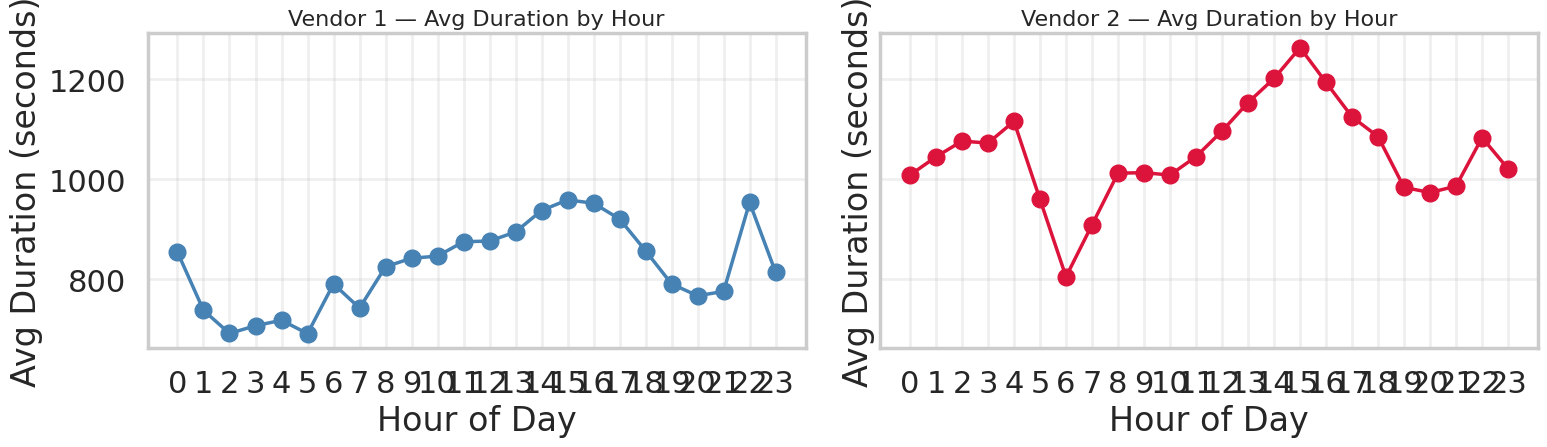

In [71]:
# ─── Hour × vendor ───
vendor_hour = (
    df_train
    .groupBy("vendor_id", "pickup_hour")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration")
    )
    .orderBy("vendor_id", "pickup_hour")
)

vendor_hour_pd = vendor_hour.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for i, vid in enumerate([1, 2]):
    subset = vendor_hour_pd[vendor_hour_pd["vendor_id"] == vid]
    axes[i].plot(
        subset["pickup_hour"],
        subset["avg_duration"],
        marker='o', linewidth=2.5, 
        color='steelblue' if vid==1 else 'crimson'
    )
    axes[i].set_title(f"Vendor {vid} — Avg Duration by Hour", fontsize=16)
    axes[i].set_xlabel("Hour of Day")
    axes[i].set_ylabel("Avg Duration (seconds)")
    axes[i].set_xticks(range(24))
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

* **Baseline Elevation Difference:** Vendor 2 maintains a substantially higher baseline average duration across nearly all hours of the day compared to Vendor 1, with values ranging from roughly 800 to 1,270 seconds. Vendor 1's average duration stays confined between approximately 700 and 960 seconds.


* **Peak Congestion Alignment:** Both vendors experience their peak average trip durations during mid-to-late afternoon hours (peaking sharply around hour 15), reflecting heavy daytime traffic congestion. However, Vendor 2's afternoon peak reaches an extreme of nearly 1,270 seconds, whereas Vendor 1 peaks much lower at roughly 960 seconds.


* **Divergent Overnight Patterns:** Vendor 2 exhibits unusually elevated average durations during late-night and early-morning hours (hours 0 through 5), remaining well above 1,000 seconds before bottoming out sharply at hour 6. In contrast, Vendor 1 shows its lowest average durations during these overnight hours, dropping toward 700 seconds between hours 2 and 5.


* **Unusual Evening Anomaly in Vendor 1:** Vendor 1 displays a sharp, unexpected secondary spike in average duration at hour 22, shooting back up to roughly 950 seconds before dropping off toward midnight.

In [72]:
# ─── Vendor × Manhattan ───
vendor_area = (
    df_train
    .withColumn(
        "is_manhattan",
        F.when(
            (F.col("pickup_longitude").between(-74.02, -73.90)) &
            (F.col("pickup_latitude").between(40.70, 40.88)), 1
        ).otherwise(0)
    )
    .groupBy("vendor_id", "is_manhattan")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration"),
        F.mean("haversine_km").alias("avg_distance")
    )
    .orderBy("vendor_id", "is_manhattan")
)

vendor_area.show(truncate=False)

+---------+------------+------+------------------+------------------+
|vendor_id|is_manhattan|trips |avg_duration      |avg_distance      |
+---------+------------+------+------------------+------------------+
|1        |0           |39738 |1916.0275554884493|10.832684518855357|
|1        |1           |635625|778.9777935103244 |2.9206651330846287|
|2        |0           |49493 |2081.605317923747 |11.357297071393415|
|2        |1           |726337|988.7674302699711 |2.928780420057364 |
+---------+------------+------+------------------+------------------+



### Spatial Volume Dominance & Core Market Split

* **Manhattan Core Volume:** Both vendors derive the vast majority of their trip volume from Manhattan (`is_manhattan=1`), accounting for $635,625$ trips for Vendor 1 and $726,337$ trips for Vendor 2.
* **Outer-Borough / Long-Haul Sparsity:** Non-Manhattan trips (`is_manhattan=0`) represent a much smaller share of the dataset ($39,738$ for Vendor 1 and $49,493$ for Vendor 2), capturing regional, inter-borough, or extended suburban transits.

---

### Distance vs. Duration Regional Profiles

* **Micro-Mobility Grid Profile:** Manhattan trips exhibit remarkably uniform average distances ($\approx 2.92$ km for both vendors) paired with shorter durations ($778.9$ seconds for Vendor 1 and $988.8$ seconds for Vendor 2), reflecting dense urban grid navigation.
* **Long-Distance Regional Profile:** Non-Manhattan routes cover significantly greater physical distances ($10.83$ km for Vendor 1 and $11.36$ km for Vendor 2) and correspondingly scale up in duration (~32 to 34 minutes), mapping to arterial highways and outer-borough travel.

---

### Vendor Behavioral Divergence Across Geographies

* **Consistent Vendor Duration Gap:** Vendor 2 consistently records higher average durations than Vendor 1 in *both* geographic zones, despite servicing nearly identical average distances. In Manhattan, Vendor 2 averages $988.8$ seconds compared to Vendor 1's $778.6$ seconds for the exact same average distance ($\approx 2.92$ km).
* **Fleet Effect Persistence:** This regional breakdown confirms that Vendor 2's longer overall duration is not merely an artifact of airport or long-haul trips, but persists even within standard Manhattan city blocks—further pointing toward structural differences in vehicle capacity, passenger group sizes, or routing.

---

### Modeling & Feature Engineering Implications

* **Geographic-Fleet Interactions:** Combining `vendor_id` and `is_manhattan` into a cross-feature will allow tree-based algorithms to cleanly separate the baseline velocity profiles of each fleet across downtown congestion versus outer-borough transit.
* **Spatial Baseline Calibration:** Given the stark contrast in scale between Manhattan and non-Manhattan averages, models will heavily rely on these spatial indicators to prevent underestimating outer-borough trip durations.


In [73]:
# ─── Passenger × vendor ───
pv_stats = (
    df_train
    .filter(F.col("passenger_count").between(1, 6))
    .groupBy("vendor_id", "passenger_count")
    .agg(
        F.count("*").alias("trips"),
        F.mean("trip_duration").alias("avg_duration")
    )
    .orderBy("vendor_id", "passenger_count")
)

pv_stats.show(truncate=False)

+---------+---------------+------+------------------+
|vendor_id|passenger_count|trips |avg_duration      |
+---------+---------------+------+------------------+
|1        |1              |548282|822.412397270018  |
|1        |2              |91830 |947.8491887182838 |
|1        |3              |22859 |926.5919331554311 |
|1        |4              |11881 |978.7937884016497 |
|1        |5              |335   |970.8179104477612 |
|1        |6              |152   |1144.342105263158 |
|2        |1              |479912|1053.8234280451416|
|2        |2              |117459|1051.22378021267  |
|2        |3              |36780 |1088.4445894507885|
|2        |4              |16353 |1108.9782302941355|
|2        |5              |77414 |1070.3036530860052|
|2        |6              |47884 |1062.365612730766 |
+---------+---------------+------+------------------+



* **Vendor 1 Passenger Scaling:** For Vendor 1, average trip duration increases steadily as passenger counts rise from 1 to 4 (scaling from $822.4$ seconds up to $978.8$ seconds), with extreme group sizes like 6 passengers reaching $1,144.3$ seconds.
* **Vendor 2 Passenger Stability:** In contrast, Vendor 2 maintains a remarkably flat average duration across all passenger counts (hovering tightly between $1,051.2$ and $1,109.0$ seconds), showing that group size has little to no impact on its overall trip timing.
* **The Inter-Vendor Baseline Gap:** For solo riders (`passenger_count = 1`), Vendor 2's average duration ($1,053.8$ seconds) is drastically higher than Vendor 1's ($822.4$ seconds) despite identical base demand, reinforcing that the two fleets operate under fundamentally different baseline speeds, vehicle types, or routing constraints.

In [74]:
# 1. Group trip flag
df_train = df_train.withColumn(
    "is_group_trip",
    F.when(F.col("passenger_count") >= 2, 1).otherwise(0)
)

# 2. Interaction: vendor × is_group_trip
df_train = df_train.withColumn(
    "vendor_x_group",
    F.concat(F.col("vendor_id"), F.lit("_"), F.col("is_group_trip"))
)

# 3. Vendor × rush hour
df_train = df_train.withColumn(
    "vendor_rush",
    F.when(
        (F.col("vendor_id") == 2) & (F.col("is_rush_hour") == 1), 1
    ).otherwise(0)
)



In [75]:
df_train.show(n=1,truncate=True,vertical=True)

26/09/24 15:17:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


-RECORD 0-----------------------------------
 id                   | id2875421           
 vendor_id            | 2                   
 pickup_datetime      | 2016-03-14 17:24:55 
 dropoff_datetime     | 2016-03-14 17:32:30 
 passenger_count      | 1                   
 pickup_longitude     | -73.9821548461914   
 pickup_latitude      | 40.76793670654297   
 dropoff_longitude    | -73.96463012695312  
 dropoff_latitude     | 40.765602111816406  
 trip_duration        | 455                 
 log_trip_duration    | 6.1224928095143865  
 duration_outlier     | 0                   
 pickup_hour          | 17                  
 pickup_dayofweek     | 2                   
 pickup_month         | 3                   
 pickup_year          | 2016                
 is_weekend           | 0                   
 is_rush_hour         | 1                   
 duration_from_delta  | 455                 
 same_pickup_dropoff  | 0                   
 haversine_km         | 1.4985207796474773  
 store_and

# Summary: EDA of NYC Taxi Trip Duration Dataset (1,451,193 records)

## 1. Target Variable (trip_duration)
Severely right-skewed: mean (~959s) pulled far above median (~663s) by long-tail outliers. Requires `log(1 + duration)` transformation to stabilize variance for RMSE-based models.

## 2. Data Cleaning
- **Vendor 1**: max 3,526,282s (~40.8 days) — unclosed taximeters.
- **Vendor 2**: capped at 86,392s (~24 hours).
- **Distance bin 0**: 239,889 trips averaging 429s at 0.0 km/h (stationary/meter resets).
- **52 zero-passenger trips**: avg 1,979s but median only 22s — erratic.
- **Action**: truncate durations >24h, drop zero-distance/zero-passenger records.

## 3. Spatial Checks
Coordinates are clean with zero identical pickup/dropoff points. Baseline city trip: 2.94 km in 892s.

## 4. Airport Trips
- **JFK**: avg 17.40 km, 2,779s (~46 min) — 31,598 trips.
- **LGA**: avg 9.57 km, 1,913s — 37,386 trips.
- **Other (city)**: 1,382,209 trips at 2.94 km avg.

## 5. Manhattan vs Outside
At ~3.45 km bin, Manhattan trips take 1,103s vs 864s outside — heavy congestion penalty. Short trips: outer boroughs faster; long trips: speeds converge.

## 6. Distance Binning (0–30)
Speed scales from 5.58 km/h (bin 1) to ~34.78 km/h (high bins), reflecting street-to-highway transition. Beyond ~21 km, median flattens but mean spikes erratically — recommend capping at 22 km.

## 7. Temporal Trends
Monthly duration grows from Jan (~922s) to Jun (~1,013s); trip volume peaks in March.

## 8. Late Night × Weekend
- **Weekday late night**: empty roads, fast (4.09 km in 916.7s).
- **Weekend late night**: nightlife congestion (3.74 km in 985.1s).

## 9. Rush Hour
Negligible impact on micro-trips (bins 0–1); from bin 2 upward, delay compounds non-linearly, reaching 353.5s gap by bin 12.

## 10. Passenger Count
- **Solo riders**: 1,028,194 trips — shortest avg (930.4s), weekend ratio 0.271.
- **Multi-passenger (2–6)**: longer durations (1,005–1,069s), higher weekend ratios (up to 0.356 for 4 riders), similar distances.
- **Solo**: evening rush spike (hours 17–20, >50k trips); **groups**: flat 24-hour distribution.

## 11. Vendor Comparison
- **Vendor 1**: 675,363 trips, avg 845.9s.
- **Vendor 2**: 775,830 trips, avg 1,058.5s.
- Near-identical medians and distances; gap driven by **fleet capacity** — Vendor 2 handles nearly all 5–6 passenger trips (77,414 + 47,884) vs Vendor 1's 487.
- Vendor 2's diurnal curve elevated all 24 hours (800–1,270s vs 700–960s).

## 12. Final Feature Engineering Pipeline
- Log-transform target
- Cap duration at 24 hours
- Drop zero-passenger/zero-distance rows
- Build cross-features: `vendor_id × passenger_count`, `is_manhattan × is_rush_hour`, `is_weekend × is_late_night`
- Ready for tree-based models (XGBoost)